## Audio processing, Video processing and Computer vision
### BSc in Data Science and Engineering - Universidad Carlos III de Madrid
### Academic year 2026/2027

# LAB SESSION 4: IMAGE CLASSIFICATION WITH CNNs (Project featuring Report + Competition)
# Predicting fire risk from satellite images

<center><img src="https://www.uc3m.es/ss/Satellite?blobcol=urldata&blobkey=id&blobtable=MungoBlobs&blobwhere=1371614316787&ssbinary=true" width="400" alt="Universidad Carlos III de Madrid logo"></center>

## Introduction

We classify fire risk from satellite images with two models: a CNN built from scratch (**custom**) and a fine-tuned pretrained network (**fine-tuned**).

- **Competition:** CodaBench, October 20 to November 9 (deadline November 9, 23:59). The submitted code is reviewed and results that cannot be reproduced are disqualified.
- **Delivery:** one `.zip` with the report and this notebook. Each team member's contributions must be stated in the report.
- **No-dependencies version:** only `db.zip` is needed; set `USE_CHECKPOINTS` in the first code cell.
- **Running the notebook:** requires `torch`, `torchvision`, `numpy`, `pandas`, `scikit-image`, `scikit-learn`, `matplotlib` and `Pillow`. Run it top to bottom; it works locally, on Google Colab and on Kaggle.

## Part 0: The problem

The goal is to predict the **fire-risk category of a satellite image** (not to detect or forecast fires). The classes, in the fixed output-column order, are:

| Index | Class | Meaning |
|---:|---|---|
| 0 | Water | bodies of water |
| 1 | Very Low | fire very unlikely to start or spread |
| 2 | Low | low risk, some factors could favour combustion |
| 3 | Moderate | intermediate risk, potentially favourable conditions |
| 4 | High | fire likely to start and spread rapidly |
| 5 | Very High | particularly favourable conditions for ignition and spread |
| 6 | Non-burnable | not enough combustible material to sustain a fire |

The source dataset is FireRisk (Shen et al., DICTA 2023, [repository](https://github.com/CharmonyShen/FireRisk)). `db.zip` holds 5,861 RGB images of **320 x 320** pixels: 3,516 for training, 1,172 for validation and 1,173 for test. Each CSV has an `id` column and a `label` column (test labels are hidden and stored as `-1`). The metric is the macro F1-score.

## Part 1: Dataset, preprocessing and augmentation

`scikit-image` reads and processes the images and `pandas` reads the CSV index files. Switches in the next cell:

- `RUN_SEARCH`: the hyper-parameter search is documented in Part 3 but never re-run here.
- `SMOKE_TEST`: tiny training subset and one epoch, only to check that the notebook executes.
- `USE_CHECKPOINTS`: `True` loads the two trained `.pt` files from `CHECKPOINT_DIR`; `False` trains both final models from scratch.
> Use `USE_CHECKPOINTS = False` if .pt files of the trained models is not available/provided. The notebook will train the models from scratch, where the configurations (exact combination of hyper-parameters, which was determined in previous deep search experiments) are already set in the code.  
  
`(FT_)PREDICT_SIZE`: size of the input image for the model at testing. If lower than original size they are transformed with CenterCrop, if higher they are resized with Resize. A model can be trained with a smaller size (*224x224*) and tested with a larger size (*320x320*).  
*Evaluation Size (used for training and validation) is fixed at 224x224 for both models. Can be found in the `ENTRY` declarations.*

In [ ]:
import os
from pathlib import Path

# Default '0' = off; change it to '1' to re-run the hyper-parameter search (it ran once outside).
RUN_SEARCH = 0
SMOKE_TEST = 0   # True: 64 training images and one epoch, only checks that it executes. If False run the full training
USE_CHECKPOINTS = False   # True: load the trained .pt files (CHECKPOINT_DIR); False: train both final models from scratch
CHECKPOINT_DIR = Path('.')   # folder with n07_60ep.pt and ft_final_swin_p2_1.pt (on Kaggle also searched in /kaggle/input)
PREDICT_SIZE = 320      # centre crop of the final val report and test predictions, custom model (320 = full image)
FT_PREDICT_SIZE = 320   # same for the fine-tuned model

# The rest of the winning configurations (architecture, training, runtime) are the ENTRY dicts: Part 1 (custom), 4.4 (FT)

In [ ]:
import hashlib
import json
import importlib.util
import math

# Determinism: these variables must be set before any CUDA work.
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['PYTHONHASHSEED'] = '42'

import copy
import gc
import numbers
import platform
import random
import shutil
import statistics
import sys
import time
import zipfile
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from skimage import exposure, filters, io, transform, util
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score

import torch
import torch._utils    # AdamW imports torch._dynamo lazily; in some torch builds that late import fails,
import torch._dynamo   # so both internals are loaded up front
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, utils, models
from torchvision.ops import StochasticDepth

Global constants, seeding and device. `PIXEL_MEAN` and `PIXEL_STD` are the ImageNet channel statistics used by the torchvision pretrained models; they centre every channel around 0 and give the fine-tuned network the input statistics it was pretrained with. The custom network uses the same normalisation.

In [ ]:
SEED = 42
CLASS_NAMES = ['Water', 'Very Low', 'Low', 'Moderate', 'High', 'Very High', 'Non-burnable']
NUM_CLASSES = len(CLASS_NAMES)
MAX_TRAIN_SAMPLES = 64 if SMOKE_TEST else 0   # 0 selects the full training split

PIXEL_MEAN = [0.485, 0.456, 0.406]
PIXEL_STD = [0.229, 0.224, 0.225]


def seed_everything(seed=SEED):
    """Seed Python, NumPy and PyTorch (CPU and CUDA) and make cuDNN deterministic."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.allow_tf32 = False   # full fp32 convolutions on Ampere+ GPUs, as on the T4 (no TF32) used for the reference runs
    torch.backends.cuda.matmul.allow_tf32 = False


def set_determinism(strict):
    """Make PyTorch raise an error on operations without a deterministic implementation (strict=True) or allow them.
    The environment variables required for deterministic CUDA are already set before PyTorch is imported."""
    torch.use_deterministic_algorithms(bool(strict))


seed_everything()
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda:0


### Environment and data preparation

One cell prepares the paths for the three supported environments and then extracts `db.zip` and checks the data:

- **Local:** `db.zip` in the working directory.
- **Google Colab:** Drive is mounted and `db.zip` is copied from `MyDrive/L4` to the local disk; results are stored in that Drive folder.
- **Kaggle:** the dataset added with "Add Input" (zip or already extracted) is located under `/kaggle/input`.

In [ ]:
IN_KAGGLE = Path('/kaggle/input').exists()
try:
    IN_COLAB = not IN_KAGGLE and importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:   # find_spec raises when the parent package 'google' is not installed
    IN_COLAB = False

if IN_KAGGLE:
    WORK = Path('/kaggle/working')
    DB_ZIP = WORK / 'db.zip'
    DATA_ROOT = WORK / 'data'
    DB_DIR = DATA_ROOT / 'db'
    zips = list(Path('/kaggle/input').rglob('db.zip'))
    csvs = list(Path('/kaggle/input').rglob('train_reduced.csv'))
    if zips:
        if not DB_ZIP.exists():
            shutil.copy(zips[0], DB_ZIP)
    elif csvs:
        DB_DIR = csvs[0].parent   # already extracted by Kaggle: nothing to unzip
        DB_ZIP = Path('/nonexistent.zip')
    else:
        raise FileNotFoundError('Add the FireRisk dataset with "Add Input" (db.zip or its extracted db/ folder).')
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK = Path('/content/drive/MyDrive/L4')
    DB_ZIP = Path('/content/db.zip')
    DATA_ROOT = Path('/content/data')
    DB_DIR = DATA_ROOT / 'db'
    if not DB_ZIP.is_file():
        shutil.copy(WORK / 'db.zip', DB_ZIP)   # local disk is much faster than Drive
else:
    WORK = Path('.')
    DB_ZIP = WORK / 'db.zip'
    DATA_ROOT = WORK / 'data'
    DB_DIR = DATA_ROOT / 'db'

OUTPUT_DIR = WORK / 'outputs' / 'Lab_4_OUT'   # predictions, manifests and submission files
SEARCH_DIR = WORK / 'search'                         # small CSVs with the hyperparameter search results
CKPT_DIR = WORK / 'outputs' / 'deep_search'          # model checkpoints (.pt files)
for directory in (OUTPUT_DIR, SEARCH_DIR, CKPT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

required_csvs = [DB_DIR / f'{split}_reduced.csv' for split in ('train', 'val', 'test')]

# Extract the DB if Zipped 
if DB_ZIP.is_file():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    restored_files = 0
    with zipfile.ZipFile(DB_ZIP) as archive:
        for member in archive.infolist():
            if not member.filename.startswith('db/'):
                continue
            target = DATA_ROOT / member.filename
            if not target.resolve().is_relative_to(DATA_ROOT.resolve()):
                raise ValueError('The archive contains an invalid dataset path.')
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            elif not target.is_file() or target.stat().st_size != member.file_size:
                archive.extract(member, DATA_ROOT)
                restored_files += 1
    print(f'Dataset ready at {DB_DIR.resolve()}; restored {restored_files} files.')

if not all(path.is_file() for path in required_csvs):
    raise FileNotFoundError(
        'Dataset CSV files were not found. Place db.zip in the working directory '
        '(or add the dataset on Kaggle / put it in MyDrive/L4 on Colab) and rerun this cell.')

for csv_path in required_csvs:
    ids = pd.read_csv(csv_path, usecols=['id'], dtype={'id': str})['id']
    for image_id in ids:
        image_path = DB_DIR / 'images' / f'{image_id}.jpg'
        if not image_path.is_file() or image_path.stat().st_size == 0:
            raise FileNotFoundError(f'Missing or empty image: {image_path}. Supply the original db.zip and rerun this cell.')
        
print('All indexed images exist and are nonempty.')

### Final-model configuration and runtime settings

No-dependencies version: the settings of the selected custom model are written in the next cell; `final/custom_final_config.json` is not read.
They are used by the DataLoaders (`num_workers`, `strict_determinism`, `preload`), the Part 2 summary and section 3.5.
`num_workers` matters because the random-crop stream of each DataLoader worker depends on the worker count;
`strict_determinism` makes PyTorch raise an error for any operation without a deterministic implementation.

In [ ]:
SELECTED = 'n07_60ep'
ENTRY = dict(
    arch=dict(base_channels=48, n_blocks=4, convs_per_block=2, kernel_size=3, head='gap', hidden=256, dropout=0.3,
              train_crop=224, eval_size=224, predict_size=PREDICT_SIZE),   # eval_size: validation during training, as in the original run
    train=dict(optimizer='adamw', lr=0.000317, weight_decay=0.0464, batch_size=128, warmup_epochs=1,
               label_smoothing=0.0, class_weights='sqrt_inv', mixup_alpha=0.0, aug='strong', epochs=60, seed=42),
    runtime=dict(num_workers=4, strict_determinism=True, pool_impl='mean', preload=False, amp=True),
    reproduce=dict(checkpoint='n07_60ep.pt',
                   checkpoint_sha256='28154f551bca71210487008cf2b955d027039dc71b97a0e99a4e7bd9413d7257',
                   submitted_csv_sha256='c6288bf17d74dd876a022d371f719b77ece43f1d6798826dab1a4ee14c48b3cf'),
    expected=dict(val_macro_f1=0.5042652706043872, best_val_f1_training=0.5024082209646386, best_epoch=36,
                  predicted_counts=[27, 378, 133, 162, 116, 57, 300]))
RUNTIME = ENTRY['runtime']

NUM_WORKERS = RUNTIME['num_workers']
STRICT_DETERMINISM = RUNTIME['strict_determinism']
if os.name == 'nt' and NUM_WORKERS > 0:   # classes defined in a notebook cannot be pickled by spawned Windows workers
    print(f'Windows: num_workers {NUM_WORKERS} -> 0 (the random crops differ from the original run).')
    NUM_WORKERS = 0
PRELOAD = RUNTIME['preload']   # True: decode the training images once into RAM (same values, faster)
set_determinism(STRICT_DETERMINISM)
print(f'Selected model: {SELECTED} | workers: {NUM_WORKERS} | strict determinism: {STRICT_DETERMINISM}')

### Dataset exploration

Class counts of the labelled splits, consistency checks on the index files and the class distribution. The classes are clearly imbalanced (Water is the rarest class, Very Low the most frequent), which motivates the class-weighted loss explored in Part 3.

Number of images in /kaggle/input/datasets/csarlvarezcascos/images/db/images: 5861
Training class counts:
label
0      86
1    1088
2     535
3     431
4     315
5     163
6     898
Name: count, dtype: int64
Validation class counts:
label
0     29
1    363
2    178
3    144
4    105
5     54
6    299
Name: count, dtype: int64


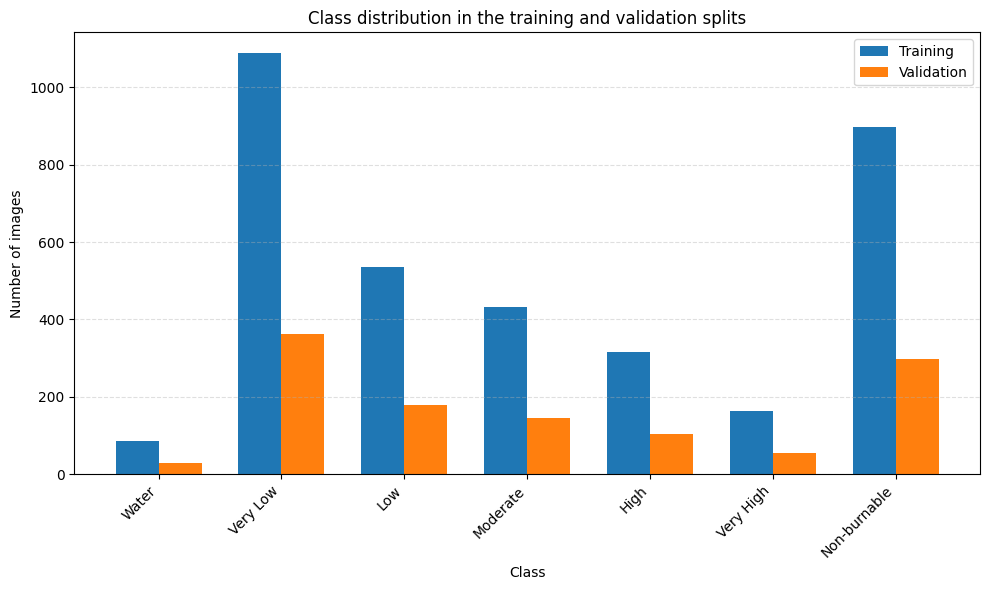

Training: 3516, validation: 1172, test: 1173


In [ ]:
image_directory = DB_DIR / 'images'
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff', '.webp'}
number_of_images = sum(path.is_file() and path.suffix.lower() in image_extensions
                       for path in image_directory.iterdir())
print(f'Number of images in {image_directory}: {number_of_images}')

df_train = pd.read_csv(DB_DIR / 'train_reduced.csv', dtype={'id': str, 'label': int})
df_val = pd.read_csv(DB_DIR / 'val_reduced.csv', dtype={'id': str, 'label': int})
df_test = pd.read_csv(DB_DIR / 'test_reduced.csv', dtype={'id': str, 'label': int})

all_labels = np.arange(NUM_CLASSES)
train_counts = df_train['label'].value_counts().reindex(all_labels, fill_value=0)
val_counts = df_val['label'].value_counts().reindex(all_labels, fill_value=0)
print(f'Training class counts:\n{train_counts}')
print(f'Validation class counts:\n{val_counts}')

for split_name, frame in [('training', df_train), ('validation', df_val)]:
    if frame.empty or not frame['label'].isin(all_labels).all():
        raise ValueError(f'The {split_name} split must have labels 0 through 6.')
    
if df_test.empty or not (df_test['label'] == -1).all():
    raise ValueError('The test split must be nonempty and have hidden labels (-1).')

if any(frame['id'].duplicated().any() for frame in (df_train, df_val, df_test)):
    raise ValueError('An index file contains duplicate image IDs.')

if (set(df_train['id']) & set(df_val['id']) or
        set(df_train['id']) & set(df_test['id']) or
        set(df_val['id']) & set(df_test['id'])):
    raise ValueError('Training, validation and test image IDs must be disjoint.')

x = np.arange(NUM_CLASSES)
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width / 2, train_counts.to_numpy(), width, label='Training')
ax.bar(x + width / 2, val_counts.to_numpy(), width, label='Validation')
ax.set_xlabel('Class')
ax.set_ylabel('Number of images')
ax.set_title('Class distribution in the training and validation splits')
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()
print(f'Training: {len(df_train)}, validation: {len(df_val)}, test: {len(df_test)}')

Inspect one training example (row 100 of the index file) with a small display helper. `image_for_display` undoes the RGB normalisation so that normalised tensors can be plotted with meaningful colours.

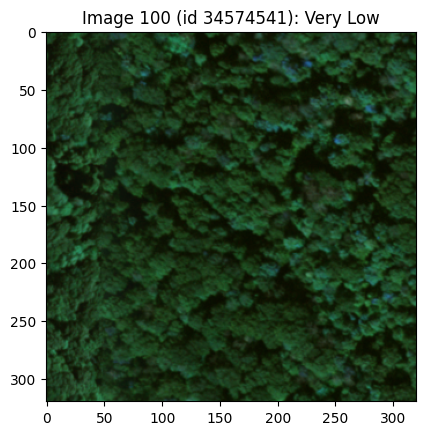

In [ ]:
def imshow(image, title_str):
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None)
    plt.title(title_str)


def image_for_display(tensor):
    """Undo the RGB normalisation and convert a CHW tensor to displayable HWC pixels."""
    image = tensor.detach().cpu()
    mean = torch.tensor(PIXEL_MEAN, dtype=image.dtype)[:, None, None]
    std = torch.tensor(PIXEL_STD, dtype=image.dtype)[:, None, None]
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


n = min(100, len(df_train) - 1)
img_id = df_train.iloc[n]['id']
label = int(df_train.iloc[n]['label'])

plt.figure()
imshow(io.imread(DB_DIR / 'images' / f'{img_id}.jpg'), f'Image {n} (id {img_id}): {CLASS_NAMES[label]}')
plt.show()

### The Dataset class

`torch.utils.data.Dataset` is the abstract interface for a PyTorch dataset. Implement a subclass with:

- `__init__`: read the index and store configuration.
- `__len__`: return the number of samples.
- `__getitem__`: read and return a sample by index.

Read image files in `__getitem__`, rather than loading the entire image collection at construction time. This limits memory use.  
If `preload=True`, the images are read once into RAM at construction time. This is faster but requires more memory.

Each sample is a dictionary: `{'image': image, 'label': label}`. The optional `transform` argument applies preprocessing and augmentation when a sample is requested. The class-name list is ordered by the numeric labels, so plot labels and output columns remain consistent.

In [ ]:
class FireRiskDataset(Dataset):
    """Read RGB images and integer labels using a CSV index.

    Args:
        csv_file: CSV with columns 'id' and 'label'.
        root_dir: Dataset directory containing the 'images' subdirectory.
        transform: Optional callable that receives and returns a sample dictionary.
        maxSize: Maximum subset size; 0 selects the full split.
        preload: Decode all images into a uint8 array in RAM (faster, uses more memory).
    """

    def __init__(self, csv_file, root_dir, transform=None, maxSize=0, preload=False):
        if not isinstance(maxSize, numbers.Integral) or maxSize < 0:
            raise ValueError('maxSize must be a nonnegative integer.')

        self.dataset = pd.read_csv(csv_file, dtype={'id': str, 'label': int})
        
        if not {'id', 'label'}.issubset(self.dataset.columns) or self.dataset.empty:
            raise ValueError('The CSV must contain nonempty id and label columns.')
        if not self.dataset['label'].isin(range(-1, NUM_CLASSES)).all():
            raise ValueError('Labels must be -1 (hidden test labels) or 0 through 6.')
        if maxSize > 0:
            indices = np.random.RandomState(SEED).permutation(len(self.dataset))
            self.dataset = self.dataset.iloc[indices[:maxSize]].reset_index(drop=True)

        self.img_dir = Path(root_dir) / 'images'
        self.transform = transform
        self.classes = CLASS_NAMES.copy()

        # PRELOAD IMAGES in CACHE
        self.cache = None
        if preload:
            first = self._read(0)
            self.cache = np.empty((len(self.dataset), *first.shape), dtype=np.uint8)
            for i in range(len(self.dataset)):
                self.cache[i] = self._read(i)

    def _read(self, idx):
        """Read one image from disk as an H x W x 3 uint8 array."""
        image = io.imread(self.img_dir / f"{self.dataset.iloc[int(idx)]['id']}.jpg")
        if image.ndim == 2:
            image = np.repeat(image[..., None], 3, axis=2)   # grayscale -> RGB
        elif image.ndim == 3 and image.shape[2] == 4:
            image = image[..., :3]                           # drop the alpha channel
        if image.ndim != 3 or image.shape[2] != 3:
            raise ValueError('Expected an RGB image with three channels.')
        return image

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        
        if torch.is_tensor(idx):
            idx = idx.item()
        idx = int(idx)
        raw = self.cache[idx] if self.cache is not None else self._read(idx)
        sample = {'image': util.img_as_float32(raw), 'label': int(self.dataset.iloc[idx]['label'])}
        return self.transform(sample) if self.transform is not None else sample

Instantiate an untransformed dataset (`raw_dataset`) to display a few samples and to try the transforms below. The training, validation and test datasets are built later in this part.

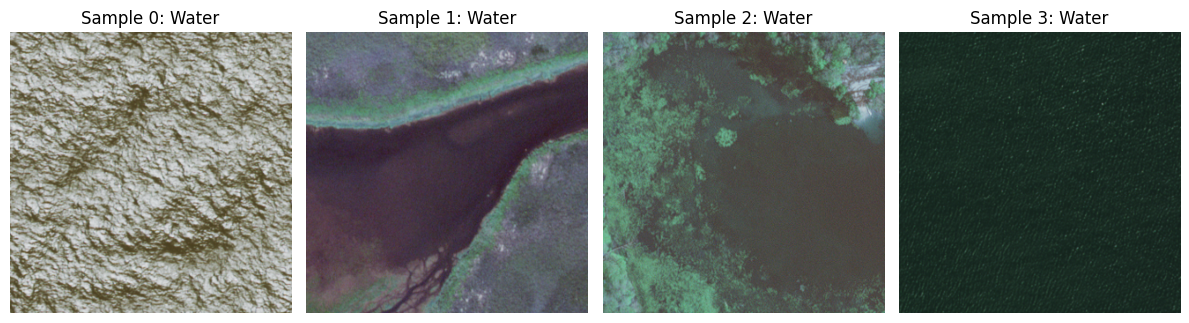

In [ ]:
raw_dataset = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR)

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for i, ax in enumerate(axes):
    sample = raw_dataset[i]
    ax.set_title(f"Sample {i}: {CLASS_NAMES[sample['label']]}")
    ax.imshow(sample['image'])
    ax.axis('off')

fig.tight_layout()
plt.show()

**IMPORTANT:** `maxSize` optionally limits the number of images by selecting a reproducible random subset. Set `maxSize=0` to use the full split.

Small subsets are useful for checking code and exploring hyperparameters quickly. Conclusions obtained from a subset may differ from those obtained with the full training split. Use the full training split for your final model.


### Preprocessing and data augmentation

Augmentation creates random variations of the training images to improve generalisation. It is applied to **training** data only; validation and test preprocessing is deterministic.
Callable transforms follow the sample-dictionary convention (parameters in `__init__`, operation in `__call__`):

- `Rescale`: resize to a shape, or resize the shorter side preserving the aspect ratio.
- `RandomCrop` (training) and `CenterCrop` (validation and test): crops must fit the image.
- `ToTensor` (`H x W x C` array to float32 `C x H x W`) and `Normalize` (per-channel mean and std).

In [ ]:
def _crop_size(output_size):
    """Return a (height, width) tuple; a single integer gives a square crop."""
    if isinstance(output_size, numbers.Integral):
        output_size = (int(output_size), int(output_size))

    if (not isinstance(output_size, tuple) or len(output_size) != 2 or
            any(not isinstance(v, numbers.Integral) or v <= 0 for v in output_size)):
        raise ValueError('Size must be a positive integer or a pair of positive integers.')
    
    return tuple(int(v) for v in output_size)


class Rescale:
    """Resize to (height, width), or resize the shorter side preserving the aspect ratio."""

    def __init__(self, output_size):
        self.output_size = (int(output_size) if isinstance(output_size, numbers.Integral)
                            else _crop_size(output_size))
        if isinstance(self.output_size, int) and self.output_size <= 0:
            raise ValueError('The output size must be positive.')

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        if isinstance(self.output_size, int):
            scale = self.output_size / min(h, w)
            new_h, new_w = round(h * scale), round(w * scale)
        else:
            new_h, new_w = self.output_size
        image = transform.resize(image, (new_h, new_w), anti_aliasing=True)
        return {'image': image.astype(np.float32), 'label': label}


class RandomCrop:
    """Choose uniformly among all valid crops, including the final row and column."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size
        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top = np.random.randint(0, h - new_h + 1)
        left = np.random.randint(0, w - new_w + 1)
        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}


class CenterCrop:
    """Take a deterministic central crop without silently changing its size."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size
        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top, left = (h - new_h) // 2, (w - new_w) // 2
        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}


class ToTensor:
    """Convert an HWC image to a contiguous float32 CHW tensor and the label to int64."""

    def __call__(self, sample):
        image = np.ascontiguousarray(sample['image'].transpose(2, 0, 1), dtype=np.float32)
        return {'image': torch.from_numpy(image),
                'label': torch.tensor(sample['label'], dtype=torch.long)}


class Normalize:
    """Apply per-channel normalisation without mutating the input tensor."""

    def __init__(self, mean, std):
        self.mean = np.asarray(mean, dtype=np.float32)
        self.std = np.asarray(std, dtype=np.float32)
        if (self.mean.ndim != 1 or self.std.shape != self.mean.shape or
                not np.isfinite(self.mean).all() or not np.isfinite(self.std).all() or
                not (self.std > 0).all()):
            raise ValueError('Mean/std must be matching finite vectors with positive std.')

    def __call__(self, sample):
        image = sample['image']
        if image.ndim != 3 or image.shape[0] != len(self.mean):
            raise ValueError('The CHW tensor and normalisation vectors must match.')
        mean = torch.as_tensor(self.mean, dtype=image.dtype, device=image.device)[:, None, None]
        std = torch.as_tensor(self.std, dtype=image.dtype, device=image.device)[:, None, None]
        return {'image': (image - mean) / std, 'label': sample['label']}

#### Exercise

Use the following cell to apply transforms. Experiment with their parameters and read each class's docstring to understand its behaviour.


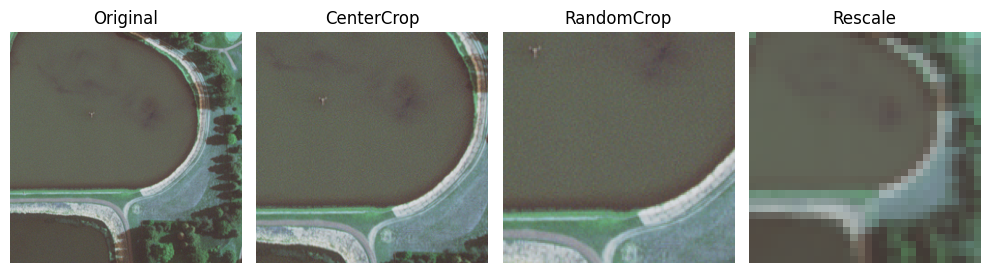

In [ ]:
sample = raw_dataset[50]

fig, axes = plt.subplots(1, 4, figsize=(10, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
for ax, tsfrm in zip(axes[1:], [CenterCrop(224), RandomCrop(150), Rescale(32)]):
    ax.imshow(tsfrm(sample)['image'])
    ax.set_title(type(tsfrm).__name__)
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

### The torchvision.transforms package

`torchvision.transforms` supplies many useful image transforms. Depending on the transform, inputs can be PIL images or PyTorch tensors. Our dataset initially returns NumPy images, so a wrapper may need to:

1. Convert the NumPy image to a PIL image.
2. Apply a torchvision transform.
3. Convert back to a NumPy image while preserving the label.

The `TVCenterCrop` class below demonstrates this pattern. This is an image-classification task: there is no segmentation mask to transform. When adapting this pattern to segmentation, image and mask geometry would need to remain aligned.


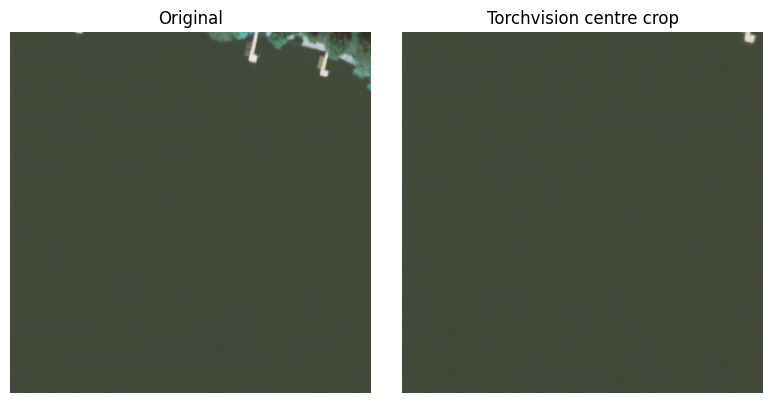

In [ ]:
class TVCenterCrop:
    """Wrap torchvision CenterCrop for a NumPy image/sample dictionary."""

    def __init__(self, size):
        self.size = _crop_size(size)
        self.crop = transforms.CenterCrop(self.size)

    def __call__(self, sample):
        image = sample['image']
        if any(crop > actual for crop, actual in zip(self.size, image.shape[:2])):
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        pil_image = Image.fromarray(util.img_as_ubyte(image))
        image = util.img_as_float32(np.asarray(self.crop(pil_image)))
        return {'image': image, 'label': sample['label']}


class TVTransform:
    """Wrap ANY PIL-based torchvision transform: NumPy float image -> PIL -> transform -> NumPy float."""

    def __init__(self, tv_transform):
        self.tv_transform = tv_transform

    def __call__(self, sample):
        pil_image = Image.fromarray(util.img_as_ubyte(sample['image']))
        image = util.img_as_float32(np.asarray(self.tv_transform(pil_image)))
        return {'image': image, 'label': sample['label']}


class TVTensorTransform:
    """Wrap a tensor-based torchvision transform (use it after ToTensor)."""

    def __init__(self, tv_transform):
        self.tv_transform = tv_transform

    def __call__(self, sample):
        return {'image': self.tv_transform(sample['image']), 'label': sample['label']}


sample = raw_dataset[min(65, len(raw_dataset) - 1)]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
axes[1].imshow(TVCenterCrop(256)(sample)['image'])
axes[1].set_title('Torchvision centre crop')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

#### Exercise

Implement other transforms that could help with this dataset, using `scikit-image` or `torchvision.transforms` as appropriate.

### Additional transforms for satellite images

- Satellite images have no "up": a flipped or rotated patch of land is the same land, so **flips and 90-degree rotations are label-preserving** and lossless.
- Gamma, blur and noise model illumination, atmosphere and sensor or JPEG differences. They must stay **mild**, because colour carries class information (green vegetation, blue water, grey non-burnable ground).

The NumPy transforms draw from `np.random` (seeded per worker by `seed_worker`); torchvision transforms use the PyTorch RNG.

In [ ]:
class RandomFlip:
    """Independent random horizontal / vertical flips (lossless); the parameters are probabilities."""

    def __init__(self, p_horizontal=0.5, p_vertical=0.5):
        self.p_horizontal, self.p_vertical = p_horizontal, p_vertical

    def __call__(self, sample):
        image = sample['image']
        if np.random.rand() < self.p_horizontal:
            image = image[:, ::-1]
        if np.random.rand() < self.p_vertical:
            image = image[::-1, :]
        return {'image': np.ascontiguousarray(image), 'label': sample['label']}


class RandomRotate90:
    """Rotate by a random multiple of 90 degrees (lossless: no interpolation, no borders)."""

    def __call__(self, sample):
        k = np.random.randint(4)
        return {'image': np.ascontiguousarray(np.rot90(sample['image'], k)), 'label': sample['label']}


class RandomRotation:
    """Rotate by a random angle in [-max_angle, max_angle] degrees (scikit-image), borders by reflection.

    Apply it before the final crop: a 224 crop of a 320 image stays inside the valid rotated area.
    """

    def __init__(self, max_angle=180):
        self.max_angle = max_angle

    def __call__(self, sample):
        angle = np.random.uniform(-self.max_angle, self.max_angle)
        image = transform.rotate(sample['image'], angle, mode='reflect', order=1)
        return {'image': image.astype(np.float32), 'label': sample['label']}


class RandomGamma:
    """Random gamma correction (scikit-image) with gamma in [1 - delta, 1 + delta]."""

    def __init__(self, delta=0.2):
        self.delta = delta

    def __call__(self, sample):
        gamma = np.random.uniform(1 - self.delta, 1 + self.delta)
        image = exposure.adjust_gamma(np.clip(sample['image'], 0, 1), gamma)
        return {'image': image.astype(np.float32), 'label': sample['label']}


class RandomGaussianBlur:
    """With probability p, blur with sigma ~ U(0.1, max_sigma) (scikit-image)."""

    def __init__(self, max_sigma=1.5, p=0.5):
        self.max_sigma, self.p = max_sigma, p

    def __call__(self, sample):
        image = sample['image']
        if np.random.rand() < self.p:
            image = filters.gaussian(image, sigma=np.random.uniform(0.1, self.max_sigma), channel_axis=-1)
        return {'image': image.astype(np.float32), 'label': sample['label']}


class RandomGaussianNoise:
    """Add zero-mean Gaussian noise with std ~ U(0, max_sigma) (pixel range [0, 1])."""

    def __init__(self, max_sigma=0.03):
        self.max_sigma = max_sigma

    def __call__(self, sample):
        sigma = np.random.uniform(0, self.max_sigma)
        image = sample['image'] + np.random.normal(0, sigma, sample['image'].shape)
        return {'image': np.clip(image, 0, 1).astype(np.float32), 'label': sample['label']}

Visual check of every transform on one image, with deliberately exaggerated parameters.

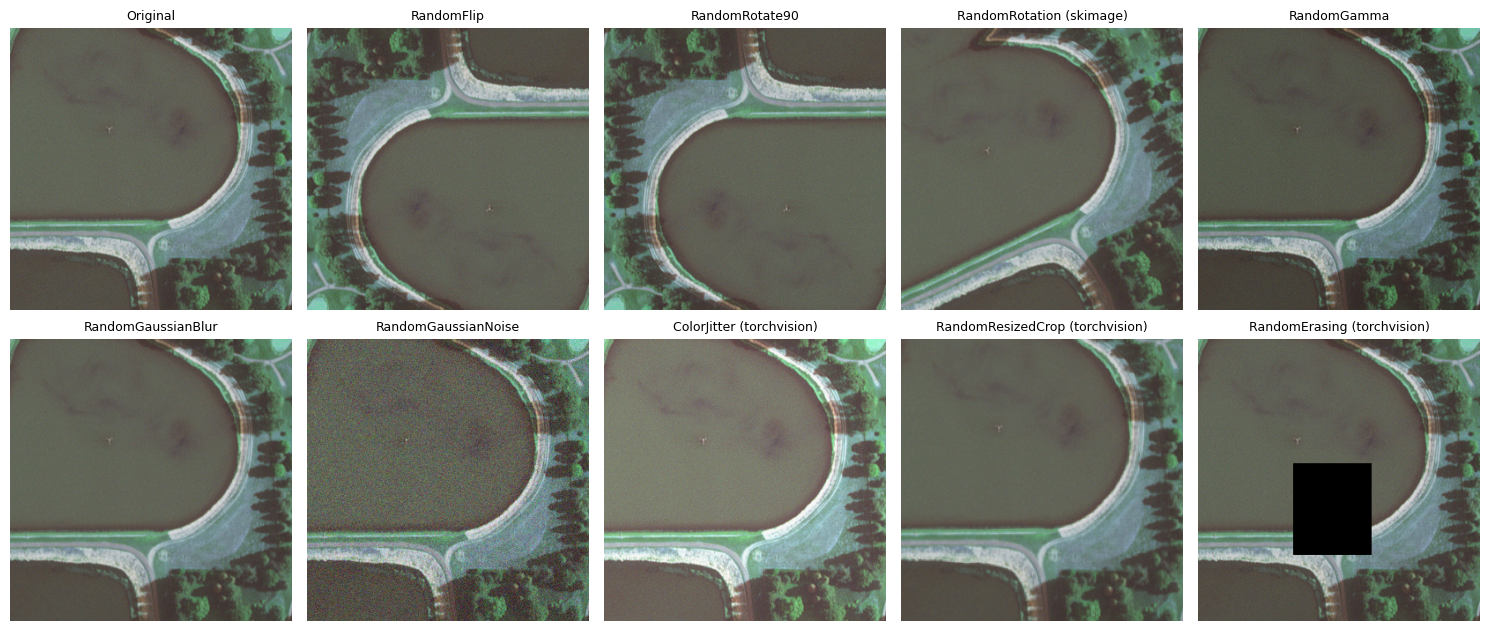

In [ ]:
sample = raw_dataset[50]
np.random.seed(SEED)
torch.manual_seed(SEED)

demo = [
    ('RandomFlip', RandomFlip(1.0, 1.0)),
    ('RandomRotate90', RandomRotate90()),
    ('RandomRotation (skimage)', RandomRotation(45)),
    ('RandomGamma', RandomGamma(0.8)),
    ('RandomGaussianBlur', RandomGaussianBlur(max_sigma=4.0, p=1.0)),
    ('RandomGaussianNoise', RandomGaussianNoise(0.12)),
    ('ColorJitter (torchvision)', TVTransform(transforms.ColorJitter(0.3, 0.3, 0.3, 0.05))),
    ('RandomResizedCrop (torchvision)', TVTransform(transforms.RandomResizedCrop(
        224, scale=(0.5, 1.0), ratio=(0.9, 1.1)))),
]

panels = [('Original', sample['image'])] + [(name, t(sample)['image']) for name, t in demo]
erased = TVTensorTransform(transforms.RandomErasing(p=1.0, scale=(0.02, 0.1), value=0))(
    ToTensor()(sample))['image']
panels.append(('RandomErasing (torchvision)', erased.permute(1, 2, 0).numpy()))

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, (title, img) in zip(axes.ravel(), panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=9)
    ax.axis('off')
fig.tight_layout()
plt.show()

### Composing transforms

The next example applies colour jitter and horizontal and vertical flips with probability 0.5, followed by tensor conversion and normalisation. Random transforms can generate many variants of an image, but they do **not** create independent observations beyond the original dataset.

Each time a training image is read, a new random transformation can be sampled. Transform parameters control the range of variation. Undo normalisation before displaying the result, so the plot shows meaningful RGB colours.


#### Exercise

Try different transform compositions and parameters. Examine how changing the order of operations affects the output.


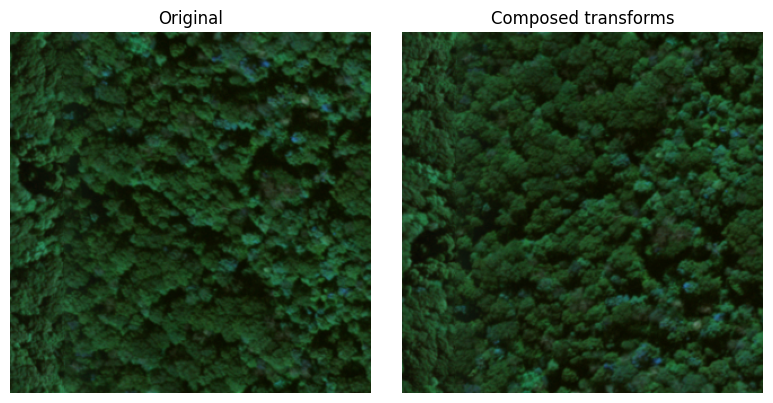

In [ ]:
composed = transforms.Compose([
    transforms.ColorJitter(brightness=0.05, contrast=0.05, saturation=0.05, hue=0.01),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(PIXEL_MEAN, PIXEL_STD),
])

sample = raw_dataset[min(100, len(raw_dataset) - 1)]
pil_sample = Image.fromarray(util.img_as_ubyte(sample['image']))
transformed_sample = composed(pil_sample)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
axes[1].imshow(image_for_display(transformed_sample))
axes[1].set_title('Composed transforms')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

**The order of the transforms matters.** The pipelines below use the same random seed, so the only difference is the order:

- Rotating the full 320 x 320 image before cropping keeps only real pixels; cropping first and rotating afterwards must invent the corners.
- Blurring after adding noise removes part of the noise; noise added after the blur stays intact.

The final training pipeline applies lossless geometry first, then a mild photometric change, then the crop, the tensor conversion and the normalisation. Validation and test use only `CenterCrop`.

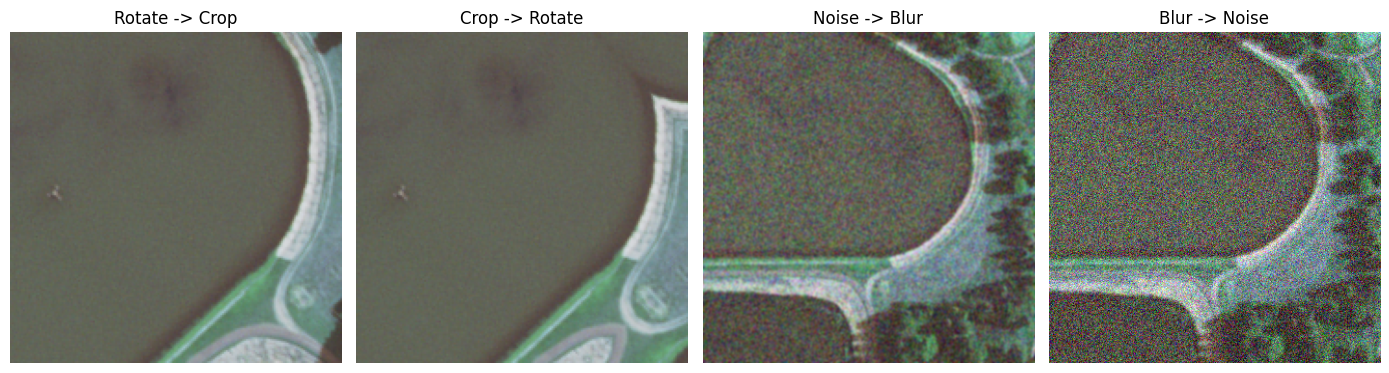

Rotate -> Crop vs Crop -> Rotate: mean abs pixel difference = 0.0135
Noise -> Blur vs Blur -> Noise: mean abs pixel difference = 0.1200


In [ ]:
def apply_pipeline(pipeline, sample, seed=4):
    """Apply a list of transforms with a fixed seed so that only the order can differ."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    return transforms.Compose(pipeline)(sample)['image']


sample = raw_dataset[50]
comparisons = [
    ('Rotate -> Crop', [RandomRotation(45), CenterCrop(180)]),
    ('Crop -> Rotate', [CenterCrop(180), RandomRotation(45)]),
    ('Noise -> Blur', [RandomGaussianNoise(0.15), RandomGaussianBlur(2.0, p=1.0)]),
    ('Blur -> Noise', [RandomGaussianBlur(2.0, p=1.0), RandomGaussianNoise(0.15)]),
]
outs = [(name, apply_pipeline(pipeline, sample)) for name, pipeline in comparisons]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (name, img) in zip(axes, outs):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis('off')
fig.tight_layout()
plt.show()
for (a, ia), (b, ib) in [outs[:2], outs[2:]]:
    h = min(ia.shape[0], ib.shape[0])
    print(f'{a} vs {b}: mean abs pixel difference = {np.abs(ia[:h, :h] - ib[:h, :h]).mean():.4f}')

CPU reference pipeline built from the transforms above. Training uses its GPU equivalent (next section), which performs the same kinds of augmentation on whole batches.

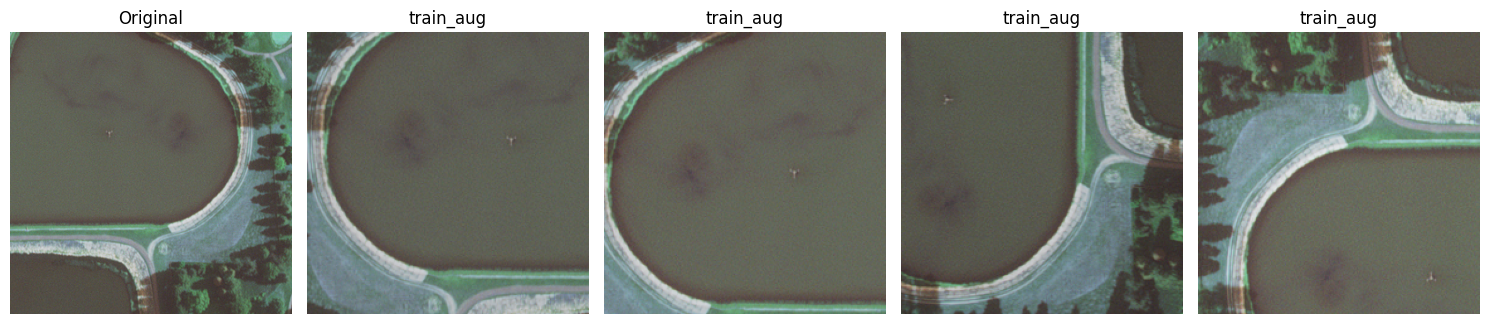

In [ ]:
train_aug = transforms.Compose([
    RandomFlip(), RandomRotate90(),                   # satellite views have no "up"
    RandomCrop(224),
    RandomGamma(0.1),                                 # mild illumination change
    TVTransform(transforms.ColorJitter(0.05, 0.05, 0.05, 0.01)),
    ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
])

sample = raw_dataset[50]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
for ax in axes[1:]:
    ax.imshow(image_for_display(train_aug(sample)['image']))
    ax.set_title('train_aug')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

### GPU augmentation (`GPUAugment` and `GPULoader`)

Per-image augmentation on the CPU is the training bottleneck, so the random augmentations run **on the GPU, on whole batches** (the CPU only crops and converts to tensors; validation and test are not augmented).

- **`GPUAugment`**: random flips, 90-degree rotations, gamma, brightness, contrast and saturation with different parameters per image, then normalisation.
- **`GPULoader`**: wraps a `DataLoader`, moves each batch to `device` and augments it there. It exposes `.dataset` and `.generator`, so `train_model` works unchanged.
- **`AUG_PRESETS`**: `light` (the defaults) and `strong` colour-jitter strengths; flips and rotations are identical in both.

In [ ]:
AUG_PRESETS = {'light': dict(gamma=0.1, brightness=0.05, contrast=0.05, saturation=0.05),
               'strong': dict(gamma=0.2, brightness=0.15, contrast=0.15, saturation=0.15)}


class GPUAugment:
    """Random augmentation and normalisation of a batch (N x 3 x H x W, floats in [0, 1]) on its device."""

    def __init__(self, mean, std, gamma=0.1, brightness=0.05, contrast=0.05, saturation=0.05):
        self.mean = torch.tensor(mean).view(1, 3, 1, 1)
        self.std = torch.tensor(std).view(1, 3, 1, 1)
        self.gamma, self.brightness, self.contrast, self.saturation = gamma, brightness, contrast, saturation

    @staticmethod
    def _factor(n, amount, device):
        return 1 + (torch.rand(n, 1, 1, 1, device=device) * 2 - 1) * amount

    @staticmethod
    def _gray(x):
        return 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]

    def __call__(self, x):
        n, dev = x.shape[0], x.device
        pick = lambda p: (torch.rand(n, device=dev) < p).view(n, 1, 1, 1)
        x = torch.where(pick(0.5), x.flip(3), x)                    # horizontal flip
        x = torch.where(pick(0.5), x.flip(2), x)                    # vertical flip
        k = torch.randint(0, 4, (n,), device=dev).view(n, 1, 1, 1)
        x = torch.where(k == 0, x, torch.where(k == 1, x.rot90(1, (2, 3)),
                        torch.where(k == 2, x.rot90(2, (2, 3)), x.rot90(3, (2, 3)))))
        x = x.clamp(1e-6, 1) ** self._factor(n, self.gamma, dev)    # gamma
        x = x * self._factor(n, self.brightness, dev)               # brightness
        m = self._gray(x).mean(dim=(1, 2, 3), keepdim=True)
        x = (x - m) * self._factor(n, self.contrast, dev) + m       # contrast
        g = self._gray(x)
        x = (x - g) * self._factor(n, self.saturation, dev) + g     # saturation
        return (x.clamp(0, 1) - self.mean.to(dev)) / self.std.to(dev)


class GPULoader:
    """Wrap a DataLoader: move each batch to `device` and apply `augment` there."""

    def __init__(self, loader, augment):
        self.loader, self.augment = loader, augment
        self.dataset, self.generator = loader.dataset, loader.generator   # train_model uses these

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        for sample in self.loader:
            x = sample['image'].to(device, dtype=torch.float32, non_blocking=True)
            yield {'image': self.augment(x), 'label': sample['label']}

### Datasets and DataLoaders

- **Training:** `RandomCrop(224)` and `ToTensor` on the CPU; normalisation and the remaining augmentation are done on the GPU by `GPUAugment`.
- **Validation and test:** deterministic `CenterCrop(224)`, `ToTensor` and `Normalize`.

`train_ds(crop)` and `eval_ds(split, size)` return datasets for other crop and evaluation sizes (for example crop 288 and evaluation 320 in the final experiments); they are cached and read the images on the fly.

In [ ]:
train_dataset = FireRiskDataset(
    DB_DIR / 'train_reduced.csv', DB_DIR, maxSize=MAX_TRAIN_SAMPLES, preload=PRELOAD,
    transform=transforms.Compose([RandomCrop(224), ToTensor()]))

val_dataset = FireRiskDataset(
    DB_DIR / 'val_reduced.csv', DB_DIR,
    transform=transforms.Compose([CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD)]))

test_dataset = FireRiskDataset(
    DB_DIR / 'test_reduced.csv', DB_DIR,
    transform=transforms.Compose([CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD)]))

_DS = {}


def train_ds(crop):
    """Training dataset for a given random-crop size (224 returns `train_dataset`)."""
    if crop == 224:
        return train_dataset
    if ('train', crop) not in _DS:
        _DS[('train', crop)] = FireRiskDataset(
            DB_DIR / 'train_reduced.csv', DB_DIR, maxSize=MAX_TRAIN_SAMPLES, preload=False,
            transform=transforms.Compose([RandomCrop(crop), ToTensor()]))
    return _DS[('train', crop)]


def eval_ds(split, size):
    """Validation or test dataset for a given centre-crop size (224 returns the default datasets)."""
    if size == 224:
        return val_dataset if split == 'val' else test_dataset
    if (split, size) not in _DS:
        _DS[(split, size)] = FireRiskDataset(
            DB_DIR / f'{split}_reduced.csv', DB_DIR,
            transform=transforms.Compose([CenterCrop(size), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD)]))
    return _DS[(split, size)]

**DataLoaders** group samples into batches and shuffle the training set. The default `collate_fn` stacks the tensors of our sample dictionaries.

- Validation and test loaders are **never shuffled**: submission rows must follow the test CSV order.
- The training generator and `seed_worker` make the shuffling and the per-worker crop streams reproducible. `NUM_WORKERS` comes from the selected configuration.
- `pin_memory` speeds up CPU to GPU copies; persistent workers avoid re-spawning workers every epoch.
- Validation and test compute no gradients, so they use a larger batch size.

In [ ]:
def seed_worker(worker_id):
    """Seed NumPy and Python `random` in each DataLoader worker from PyTorch's worker seed."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


train_generator = torch.Generator().manual_seed(SEED)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT = NUM_WORKERS > 0

train_dataloader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker, generator=train_generator,
    pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT)

val_dataloader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT)

test_dataloader = DataLoader(
    test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT)

print(f'Samples: train {len(train_dataset)}, validation {len(val_dataset)}, test {len(test_dataset)}')

Samples: train 3516, validation 1172, test 1173


Visual check of a training batch: the 224 x 224 random crops produced by the dataset (top) and the same crops after `GPUAugment` with the `light` preset (bottom, normalisation undone for display).

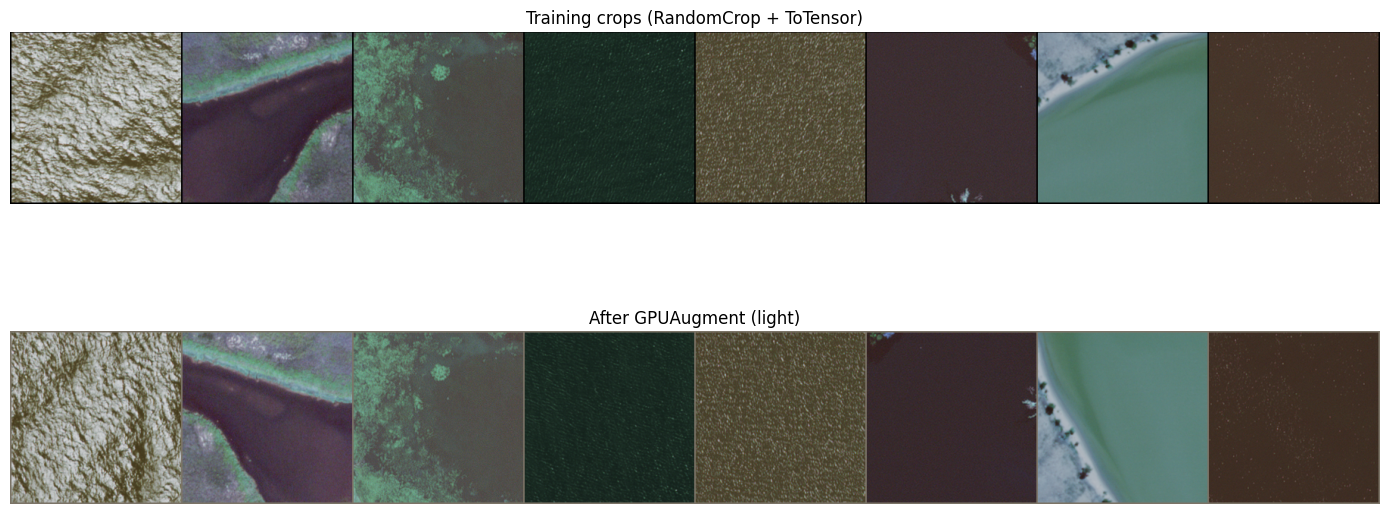

In [ ]:
batch = torch.stack([train_dataset[i]['image'] for i in range(min(8, len(train_dataset)))])
augmented = GPUAugment(PIXEL_MEAN, PIXEL_STD, **AUG_PRESETS['light'])(batch)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].imshow(utils.make_grid(batch, nrow=len(batch)).permute(1, 2, 0).numpy())
axes[0].set_title('Training crops (RandomCrop + ToTensor)')
axes[1].imshow(image_for_display(utils.make_grid(augmented, nrow=len(batch))))
axes[1].set_title('After GPUAugment (light)')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

## Part 2: Building a custom fire-risk network

`CustomNet` is a CNN built from scratch: it maps a batch `N x 3 x S x S` to `N x 7` raw logits.
Softmax is applied only when probabilities are needed (reports, submission); the loss takes logits.

The hyper-parameters are split in two dictionaries: `ARCH_CFG` (what the network is) and `TRAIN_CFG` (how it is trained).
Their values below are the **course reference setup**; the final model uses the hard-coded `ENTRY` of Part 1.

In [ ]:
# Architecture: filters of block i = min(base_channels * 2**i, 512)
ARCH_CFG = dict(
    base_channels=32,      # filters of the first block
    n_blocks=4,            # conv blocks, each ending in a 2 x 2 max-pool
    convs_per_block=1,     # Conv-BN-ReLU layers per block (2 = VGG style)
    kernel_size=3,         # conv kernel, stride 1, padding kernel_size // 2
    head='flatten',        # 'flatten' = Flatten -> fc1, 'gap' = global average pooling -> fc1
    hidden=128,            # units of the first fully connected layer
    dropout=0.5,           # dropout before the output layer (0 = off)
    train_crop=224,        # side of the square crop given to the network in training
    eval_size=224,         # side of the centre crop used in validation / test
)

# Training: optimiser, schedule, loss and regularisation
TRAIN_CFG = dict(
    optimizer='sgd',       # 'sgd' (Nesterov, momentum 0.9) or 'adamw'
    lr=1e-3,
    weight_decay=5e-4,
    batch_size=64,
    warmup_epochs=1,       # linear warm-up epochs of the cosine schedule used by build_run
    label_smoothing=0.0,
    class_weights='none',  # 'none' | 'sqrt_inv' (1/sqrt(n)) | 'inv' (1/n)
    mixup_alpha=0.0,       # 0 = off
    aug='light',           # GPUAugment preset: 'light' | 'strong'
    epochs=30,
    seed=SEED,
)

REFERENCE_CFG = {**ARCH_CFG, **TRAIN_CFG}

### 2.1 Network

`[Conv(k x k) -> BatchNorm -> ReLU] x convs_per_block -> MaxPool(2 x 2)` repeated for every block, then
flatten (or global average pooling) -> `fc1` -> ReLU -> Dropout -> `fc2`.  

The input size of `fc1` is computed from the crop size, kernel and number of blocks.  

Two options let both training environments be rebuilt: `head` (`flatten` | `gap`) and `pool_impl`
(`adaptive`: `nn.AdaptiveAvgPool2d(1)`; `mean`: `x.mean((2, 3))`, same output but deterministic on CUDA).

In [ ]:
class GlobalAvgPool(nn.Module):
    """Global average pooling as a plain mean: same output as AdaptiveAvgPool2d(1), deterministic on CUDA."""

    def forward(self, x):
        return x.mean(dim=(2, 3), keepdim=True)


class CustomNet(nn.Module):
    """CNN from scratch: N x 3 x S x S  ->  N x 7 raw logits (softmax lives in the loss).

    [[Conv(k x k) -> BatchNorm -> ReLU] x convs_per_block -> MaxPool(2 x 2)] x len(channels) -> Flatten (or global
    average pooling if head='gap') -> fc1 -> ReLU -> Dropout -> fc2
    """

    def __init__(self, channels=(32, 64, 128, 256), kernel_size=3, padding=1, hidden=128, dropout=0.0,
                 batch_norm=True, input_size=224, num_classes=NUM_CLASSES, convs_per_block=1,
                 head='flatten', pool_impl='mean'):
        super().__init__()
        if head not in ('flatten', 'gap'):
            raise ValueError("head must be 'flatten' or 'gap'.")
        if pool_impl not in ('adaptive', 'mean'):
            raise ValueError("pool_impl must be 'adaptive' or 'mean'.")

        blocks, in_channels, in_size = [], 3, input_size
        for out_channels in channels:
            for _ in range(convs_per_block):   # first conv: in_channels -> out_channels, the others keep out_channels
                blocks.append(nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding))
                if batch_norm:                 # before the ReLU: stabilises activations and gradients
                    blocks.append(nn.BatchNorm2d(out_channels))
                blocks.append(nn.ReLU(inplace=True))
                in_size = in_size - kernel_size + 2 * padding + 1   # conv: size - k + 2p + 1
                in_channels = out_channels
            blocks.append(nn.MaxPool2d(2))
            in_size //= 2                                           # pool: floor(size / 2)
        if in_size < 1:
            raise ValueError('The input is too small for this number of blocks.')

        self.features = nn.Sequential(*blocks)   # convolutional part: input images -> feature maps

        # 'gap' leaves one value per channel; 'flatten' keeps the whole last map (C * H * W)
        if head == 'gap':
            self.pool = GlobalAvgPool() if pool_impl == 'mean' else nn.AdaptiveAvgPool2d(1)
        else:
            self.pool = nn.Identity()
        flat_features = in_channels if head == 'gap' else in_channels * in_size * in_size

        self.classifier = nn.Sequential(
            nn.Linear(flat_features, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(hidden, num_classes))

        for m in self.modules():   # He initialisation for the ReLU convolutions
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.pool(self.features(x))   # N x C x H x W  (N x C x 1 x 1 with head='gap')
        return self.classifier(x.flatten(1))


def build_model(cfg):
    """CustomNet on `device` from a flat config dict (ARCH_CFG keys, optional `pool_impl`)."""
    k = cfg.get('kernel_size', 3)
    channels = tuple(min(cfg['base_channels'] * 2 ** i, 512) for i in range(cfg['n_blocks']))
    return CustomNet(channels=channels, kernel_size=k, padding=k // 2, hidden=cfg['hidden'], dropout=cfg['dropout'],
                     batch_norm=True, input_size=cfg.get('train_crop', 224), convs_per_block=cfg['convs_per_block'],
                     head=cfg['head'], pool_impl=cfg.get('pool_impl', 'mean')).to(device)

### 2.2 Architecture summary

Layer-by-layer output shapes and parameter counts of the reference network and of the selected final model
(`ENTRY` in Part 1).

In [ ]:
def architecture_table(model, input_size):
    """One row per conv / pool / linear layer: output shape and number of parameters."""
    rows, hooks = [], []
    for name, layer in model.named_modules():
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Linear, GlobalAvgPool, nn.AdaptiveAvgPool2d)):
            hooks.append(layer.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append(dict(
                    layer=f'{name} ({type(mod).__name__})', output=tuple(out.shape[1:]),
                    params=sum(p.numel() for p in mod.parameters())))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, input_size, input_size, device=device))
    model.train(was_training)
    for hook in hooks:
        hook.remove()
    return pd.DataFrame(rows)


networks = [('Reference network', ARCH_CFG),
            (f'Final network ({SELECTED})', {**ENTRY['arch'], 'pool_impl': RUNTIME['pool_impl']})]

for title, arch in networks:
    net = build_model(arch)
    table = architecture_table(net, arch['train_crop'])
    print(f'{title}: {sum(p.numel() for p in net.parameters()):,} trainable parameters')
    display(table)
    del net

## Part 3: Training the network

We now define the evaluation metric, loss, optimiser and learning-rate schedule.

### Evaluation metric: macro F1

For a class, precision is the fraction of predicted positives that are correct, and recall is the fraction of actual positives correctly identified:

$$\operatorname{precision}=\frac{TP}{TP+FP},\qquad
\operatorname{recall}=\frac{TP}{TP+FN}.$$

F1 is their harmonic mean:

$$F_1=\frac{2\,\operatorname{precision}\,\operatorname{recall}}
{\operatorname{precision}+\operatorname{recall}}
=\frac{2TP}{2TP+FP+FN}.$$

For seven classes, macro F1 gives each class equal weight:

$$\operatorname{MacroF1}=\frac{1}{7}\sum_{c=0}^{6}F_{1,c}.$$

We explicitly include all seven labels. Undefined per-class scores are assigned zero, which makes evaluation well-defined when a small split omits a class. Macro F1 highlights class-level performance under imbalance, but it should still be inspected alongside per-class results.

### Confusion matrix

Rows represent **true classes** and columns represent **predicted classes**. A row-normalised matrix divides each row by the number of true examples in that class. The display uses percentages and the fixed numeric class order. A class with no true examples has a zero row, rather than an undefined division.

Background references: [F-score](https://en.wikipedia.org/wiki/F-score#Macro_F1) and [confusion matrix](https://en.wikipedia.org/wiki/Confusion_matrix).


### 3.1 Loss, optimiser and schedule

- **Loss:** cross-entropy on logits, optionally with class weights (`sqrt_inv` = 1/sqrt(n), `inv` = 1/n, normalised to mean 1) and label smoothing.
- **Optimiser:** AdamW, or SGD with Nesterov momentum 0.9, as set in the configuration.
- **Schedule:** stepped once per epoch: linear warm-up, then cosine decay to zero over the remaining epochs.

`build_run(cfg, epochs)` creates the model, loss, optimiser, scheduler and data loaders of one configuration
(a flat dict with the keys of `ARCH_CFG` and `TRAIN_CFG`). It reads the seed, the training crop and the evaluation size from `cfg`.

In [ ]:
def class_weight_tensor(kind):
    """None, or class weights normalised to mean 1: 'sqrt_inv' = 1/sqrt(n), 'inv' = 1/n (n = training class counts)."""
    if kind == 'none':
        return None
    counts = np.bincount(train_dataset.dataset['label'], minlength=NUM_CLASSES)[:NUM_CLASSES]
    counts = np.maximum(counts, 1).astype(np.float64)
    w = 1 / np.sqrt(counts) if kind == 'sqrt_inv' else 1 / counts
    return torch.tensor(w / w.mean(), dtype=torch.float32, device=device)


def build_run(cfg, epochs):
    """Model, loss, optimiser, scheduler and loaders for one configuration."""
    seed = cfg['seed']
    seed_everything(seed)
    model = build_model(cfg)
    criterion = nn.CrossEntropyLoss(weight=class_weight_tensor(cfg['class_weights']),
                                    label_smoothing=cfg['label_smoothing'])
    if cfg['optimizer'] == 'adamw':
        optimizer = optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    else:
        optimizer = optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True,
                              weight_decay=cfg['weight_decay'])
    w = cfg['warmup_epochs']   # stepped once per epoch: linear warm-up, then cosine decay to 0
    scheduler = lr_scheduler.LambdaLR(optimizer, lambda e: (e + 1) / (w + 1) if e < w else
                                      0.5 * (1 + math.cos(math.pi * (e - w) / max(1, epochs - w))))
    train_loader = DataLoader(train_ds(cfg['train_crop']), batch_size=cfg['batch_size'], shuffle=True,
                              num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                              generator=torch.Generator().manual_seed(seed),
                              pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(eval_ds('val', cfg['eval_size']), batch_size=64, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    loaders = {'train': GPULoader(train_loader, GPUAugment(PIXEL_MEAN, PIXEL_STD, **AUG_PRESETS[cfg['aug']])),
               'val': val_loader}
    return model, criterion, optimizer, scheduler, loaders

### 3.2 Training function

Each epoch trains (backpropagation and optimiser step), then evaluates in validation mode without gradients.  
The weights of the epoch with the highest validation macro F1 are restored at the end: this is
**best-checkpoint selection, not early stopping**, as every epoch runs (only the optional `epoch_callback` can stop earlier,
which the search uses for **pruning**).  

Optional arguments: `amp` (fp16 autocast), `mixup_alpha`, `mix_prob` (probability of mixing a batch; Part 4 uses 1.0,
which draws one random number per batch), `loaders`, `verbose` and `history` (one dict of losses and F1 per epoch).

In [ ]:
def train_model(model, criterion, optimizer, scheduler,
                num_epochs=25, plot_confusion_matrix=True, *,
                loaders=None, amp=False, mixup_alpha=0.0, mix_prob=None, epoch_callback=None, verbose=True, history=None):
    """Train for a fixed number of epochs and return the model with the best validation macro F1.

    Best-checkpoint selection, not early stopping: all `num_epochs` run unless `epoch_callback(info)` returns True.
    Optional: `loaders` (dict 'train'/'val'; default global `dataloaders`), `amp` (fp16 autocast on CUDA),
    `mixup_alpha` (> 0: mixup), `mix_prob` (None: mix every batch, no extra random draw; a float: mix a batch only if
    `np.random.rand() < mix_prob`, one draw per training batch), `verbose=False` (one compact line per epoch), `history` (list; one dict per epoch
    with epoch, train_loss, train_f1, val_loss, val_f1 is appended to it).
    """

    loaders = dataloaders if loaders is None else loaders
    use_amp = bool(amp) and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    if not isinstance(num_epochs, numbers.Integral) or num_epochs < 1:
        raise ValueError('num_epochs must be a positive integer.')
    if not isinstance(criterion, nn.CrossEntropyLoss) or criterion.reduction != 'mean':
        raise ValueError('Use CrossEntropyLoss with reduction="mean".')
    if any(len(loaders[phase].dataset) == 0 for phase in ('train', 'val')):
        raise ValueError('Training and validation datasets must be nonempty.')

    seed_everything()

    if loaders['train'].generator is not None:
        loaders['train'].generator.manual_seed(SEED)

    criterion = criterion.to(device)

    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = -float('inf')
    best_predictions = best_labels = None
    labels_order = np.arange(NUM_CLASSES)

    for epoch in range(num_epochs):
        if verbose:
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

        for phase in ('train', 'val'):
            model.train(phase == 'train')
            running_loss = 0.0
            loss_denominator = 0.0
            phase_predictions, phase_labels = [], []

            for sample in loaders[phase]:
                inputs = sample['image'].to(device, dtype=torch.float32)
                labels = sample['label'].to(device, dtype=torch.long)

                mixing = phase == 'train' and mixup_alpha > 0 and (mix_prob is None or np.random.rand() < mix_prob)
                if mixing:   # mixup: blend each image with a shuffled partner of the same batch
                    lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                    perm = torch.randperm(inputs.shape[0], device=inputs.device)
                    inputs = lam * inputs + (1 - lam) * inputs[perm]

                if phase == 'train':
                    optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase == 'train'):
                    with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                        logits = model(inputs)
                        if logits.shape != (labels.numel(), NUM_CLASSES):
                            raise ValueError('The network must return N x 7 logits.')
                        if mixing:
                            loss = lam * criterion(logits, labels) + (1 - lam) * criterion(logits, labels[perm])
                        else:
                            loss = criterion(logits, labels)
                    if not torch.isfinite(loss):
                        raise ValueError('Non-finite loss; check inputs and optimiser settings.')
                    if phase == 'train':
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()

                denominator = (labels.numel() if criterion.weight is None else
                               criterion.weight[labels].sum().item())
                running_loss += loss.item() * denominator
                loss_denominator += denominator
                phase_predictions.append(logits.detach().argmax(dim=1).cpu().numpy())
                phase_labels.append(labels.detach().cpu().numpy())   # original labels, also with mixup

            if phase == 'train' and scheduler is not None:
                scheduler.step()
            predictions = np.concatenate(phase_predictions)
            true_labels = np.concatenate(phase_labels)
            epoch_loss = running_loss / loss_denominator
            epoch_f1 = f1_score(true_labels, predictions, labels=labels_order,
                                average='macro', zero_division=0)
            if verbose:
                print(f'{phase} Loss: {epoch_loss:.4f} Macro F1-score: {epoch_f1:.4f}')
            if phase == 'train':
                train_loss, train_f1 = epoch_loss, epoch_f1
            if phase == 'val' and epoch_f1 > best_f1:
                best_f1 = epoch_f1
                best_model_wts = copy.deepcopy(model.state_dict())
                best_predictions = predictions.copy()
                best_labels = true_labels.copy()
        if verbose:
            print()
        else:
            print(f'ep {epoch + 1:2d}/{num_epochs}  train loss {train_loss:.3f} F1 {train_f1:.3f} | '
                  f'val loss {epoch_loss:.3f} F1 {epoch_f1:.3f}  (best {best_f1:.3f})')

        if history is not None:
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), train_f1=float(train_f1),
                                val_loss=float(epoch_loss), val_f1=float(epoch_f1)))

        if epoch_callback is not None and epoch_callback(dict(
                epoch=epoch, train_loss=train_loss, train_f1=train_f1,
                val_loss=epoch_loss, val_f1=epoch_f1, best_f1=best_f1)):
            print(f'Pruned after epoch {epoch + 1}')
            break

    model.load_state_dict(best_model_wts)
    model.eval()

    elapsed = time.time() - since
    print(f'Training complete in {int(elapsed // 60)}m {int(elapsed % 60)}s')
    print(f'Best validation macro F1-score: {best_f1:.6f}')

    if plot_confusion_matrix:
        cm = confusion_matrix(best_labels, best_predictions, labels=labels_order,
                              normalize='true')
        cm_display = ConfusionMatrixDisplay(100 * cm, display_labels=CLASS_NAMES)
        cm_display.plot(xticks_rotation='vertical', values_format='.1f')
        plt.title('Row-normalised confusion matrix (%)')
        plt.tight_layout()
        plt.show()

    return model

### 3.3 Reference training (not run by default)

The reference network of Part 2 trained with the course settings: SGD with momentum, `StepLR` (learning rate x 0.1 every 7 epochs),
plain cross-entropy and the light GPU augmentation.  
It reaches a macro F1 of about 0.36 on validation:
the step schedule shrinks the learning rate too early, which motivated the cosine schedule and the search of section 3.4.  

Set `TRAIN_REFERENCE = True` to repeat it. The unweighted `criterion` and the `dataloaders` defined here are also
used by the fine-tuning in Part 4.

In [ ]:
TRAIN_REFERENCE = False

criterion = nn.CrossEntropyLoss()
dataloaders = {'train': GPULoader(train_dataloader, GPUAugment(PIXEL_MEAN, PIXEL_STD)), 'val': val_dataloader}

if TRAIN_REFERENCE:
    seed_everything()
    referenceNet = build_model(REFERENCE_CFG)
    optimizer_ref = optim.SGD(referenceNet.parameters(), lr=REFERENCE_CFG['lr'], momentum=0.9,
                              weight_decay=REFERENCE_CFG['weight_decay'])
    scheduler_ref = lr_scheduler.StepLR(optimizer_ref, step_size=7, gamma=0.1)
    referenceNet = train_model(referenceNet, criterion, optimizer_ref, scheduler_ref,
                               num_epochs=REFERENCE_CFG['epochs'])

### Prediction helper

`predict_probs` returns softmax probabilities and labels of a dataset in its original (unshuffled) order.
The forward pass is fp32; `dtype` only sets the type of the returned array (the fine-tuning predictions use `batch_size=64`, `dtype=np.float64`).

In [ ]:
@torch.no_grad()
def predict_probs(model, dataset, batch_size=128, dtype=np.float32):
    """Softmax probabilities (N x 7, `dtype`) and labels of `dataset`, in dataset order (fp32 forward pass)."""
    model.eval()
    probabilities, labels = [], []
    for sample in DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0):
        logits = model(sample['image'].to(device, dtype=torch.float32))
        probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
        labels.append(sample['label'].numpy())
    return np.concatenate(probabilities).astype(dtype), np.concatenate(labels)

## 3.4 Hyper-parameter search (documented, not re-run)

The search ran **once, outside this notebook** (in Kaggle, during hours of computation); its results are read from the CSV files in `SEARCH_DIR` (`search/`). The no-dependencies version does not include them: the display cells only print a notice.
- Phases 1-2: two computers (or more) (`MACHINE_ID` 0 and 1); trial `i` ran on machine `i % N_MACHINES`.  
    - Between both phases, the computers shared their `.csv` results in `SEARCH_DIR` so each one knew the best global configs from phase 1, to be used in phase 2. 
- Phases 3-5: one computer
- Phases 1-3 used `AdaptiveAvgPool2d` and non-strict determinism; only phase 5 retrains bit-exactly.
- `RUN_SEARCH = False` (Part 1) skips every execution cell below, so the notebook only trains the final model.

**Fixed Hyperparameters** in all trials: 3x3 convs, BatchNorm, ReLU, 2x2 max-pool, cosine decay with 1 warm-up epoch, AMP, seed 42, crop 224.

**Phase 1 - 24 random trials from every possible combination, 15 epochs, median-stopping pruning after epochs 4 and 8**

| Group | Hyper-parameter | Explored values |
|---|---|---|
| Architecture | `base_channels` (block `i` has `min(base * 2**i, 512)` filters) | 24, 32, 48 |
| Architecture | `n_blocks` | 4, 5 |
| Architecture | `convs_per_block` | 1, 2 |
| Architecture | `head` | `gap`, `flatten` |
| Training | `optimizer` | `adamw`, `sgd` (Nesterov, momentum 0.9) |
| Training | `lr` | AdamW: log-uniform [2e-4, 3e-3]; SGD: log-uniform [5e-3, 1e-1] |
| Training | `weight_decay` | fixed: 0.05 (AdamW), 5e-4 (SGD) |

**Phase 2 - 16 random trials around the best phase-1 trial (architecture and optimiser inherited), 15 epochs, pruning after epochs 6 and 10**

| Group | Hyper-parameter | Explored values |
|---|---|---|
| Architecture | `hidden` (fc1 units) | 128, 256 |
| Architecture | `dropout` | 0.0, 0.2, 0.3, 0.5 |
| Training | `lr` | best lr x 2^U(-1, 1) |
| Training | `weight_decay` | AdamW: log-uniform [5e-3, 0.2]; SGD: log-uniform [1e-4, 2e-3] |
| Training | `batch_size` | 32, 64, 128 |
| Training | `label_smoothing` | 0.0, 0.1 |
| Training | `class_weights` | `none`, `sqrt_inv` (1/sqrt(class count)) |
| Training | `mixup_alpha` | 0.0, 0.2, 0.4 |
| Training | `aug` | `light` (GPUAugment defaults), `strong` (about 3x the colour/gamma jitter) |

**Phases 3-5 - longer runs without pruning (only the changes with respect to the parent configuration are listed)**

| Phase | Runs | Architecture changes | Training changes |
|---|---|---|---|
| 3 | top-3 configs after phase 3, 40 epochs | none | none (cosine stretched to 40 epochs) |
| 4 | one change at a time, 40 epochs | `base_channels` 48 or 64 with `convs_per_block` 2 | `class_weights` `inv` (1/n); `dropout` 0 and `aug` light |
| 5 | 12 strict-deterministic runs on the two 48x2 bases, seeds 42-44 | `base_channels` 64, `n_blocks` 5, crop 288 / eval 320 | 60 epochs, seeds 43 and 44, combination of width + 60 ep + 288/320 |

In [ ]:
# Two-computer split of phases 1-2: the ONLY value that differs between the computers is MACHINE_ID.
MACHINE_ID = 1          # 0 or 1
N_MACHINES = 2          # trial i of a phase runs on machine i % N_MACHINES (1 = run every trial on this computer)

SEARCH_EPOCHS = 15                            # budget per trial in phases 1-2
PRUNE_EPOCHS = {'p1': (4, 8), 'p2': (6, 10)}  # median-stopping checks, as observed in the stored `epochs_run`
MIN_TRIALS_FOR_PRUNING = 4                    # finished trials of the phase needed before pruning starts
SEARCH_AMP = device.type == 'cuda'            # fp16 mixed precision
N_PHASE1, N_PHASE2 = 24, 16                   # random trials per phase (over all computers)
N_FINALISTS, FINALIST_EPOCHS = 3, 40            # phase 3: configs retrained, and epochs

# Starting point: every trial changes some of these values and keeps the rest.
BASE_CFG = dict(base_channels=32, n_blocks=4, convs_per_block=1, head='gap', kernel_size=3,
                hidden=128, dropout=0.3,
                optimizer='adamw', lr=1e-3, weight_decay=0.05, batch_size=64, warmup_epochs=1,
                label_smoothing=0.0, class_weights='none', mixup_alpha=0.0, aug='light',
                train_crop=224, eval_size=224, seed=SEED)

ARCH_KEYS = ['base_channels', 'n_blocks', 'convs_per_block', 'head', 'hidden', 'dropout']
TRAIN_KEYS = ['optimizer', 'lr', 'weight_decay', 'batch_size', 'label_smoothing', 'class_weights',
              'mixup_alpha', 'aug']

Generation of the random search of hyperparameters combinations

In [ ]:
# ---- search spaces (seeded: identical lists on every computer) ----
def _loguniform(rng, lo, hi):
    return math.exp(rng.uniform(math.log(lo), math.log(hi)))

def _round3(v):
    return float(f'{v:.3g}')   # 3 significant digits keeps the CSV readable

def sample_phase1(n, seed=SEED):
    """Primary hyper-parameters: optimiser, lr, width, depth, convs per block, head."""
    rng, configs = random.Random(seed + 1), []
    for i in range(n):
        cfg = dict(BASE_CFG)
        cfg['optimizer'] = rng.choice(['adamw', 'sgd'])
        if cfg['optimizer'] == 'adamw':
            cfg['lr'], cfg['weight_decay'] = _round3(_loguniform(rng, 2e-4, 3e-3)), 0.05
        else:
            cfg['lr'], cfg['weight_decay'] = _round3(_loguniform(rng, 5e-3, 1e-1)), 5e-4
        cfg['base_channels'] = rng.choice([24, 32, 48])
        cfg['n_blocks'] = rng.choice([4, 5])
        cfg['convs_per_block'] = rng.choice([1, 2])
        cfg['head'] = rng.choice(['gap', 'flatten'])
        cfg['trial_id'] = f'p1_{i:02d}'
        configs.append(cfg)
    return configs

def sample_phase2(best, n, seed=SEED):
    """Secondary hyper-parameters around `best` (keeps its architecture and optimiser)."""
    rng, configs = random.Random(seed + 2), []
    for i in range(n):
        cfg = dict(best)
        cfg['lr'] = _round3(best['lr'] * 2 ** rng.uniform(-1, 1))
        lo, hi = (5e-3, 0.2) if best['optimizer'] == 'adamw' else (1e-4, 2e-3)
        cfg['weight_decay'] = _round3(_loguniform(rng, lo, hi))
        cfg['dropout'] = rng.choice([0.0, 0.2, 0.3, 0.5])
        cfg['hidden'] = rng.choice([128, 256])
        cfg['batch_size'] = rng.choice([32, 64, 128])
        cfg['label_smoothing'] = rng.choice([0.0, 0.1])
        cfg['class_weights'] = rng.choice(['none', 'sqrt_inv'])
        cfg['mixup_alpha'] = rng.choice([0.0, 0.2, 0.4])
        cfg['aug'] = rng.choice(['light', 'strong'])
        cfg['trial_id'], cfg['parent'] = f'p2_{i:02d}', best['trial_id']
        configs.append(cfg)
    return configs

In [ ]:

NO_SEARCH_MSG = 'Search results are not included in the no-dependencies version (see the repository `search/` folder).'

# ---- results store: one CSV per machine and phase in SEARCH_DIR, merged when read ----
RESULT_COLS = ['trial_id', 'phase', 'machine', 'status', 'best_val_f1', 'best_epoch', 'epochs_run',
               'minutes', 'params', 'gpu', 'val_f1_history', 'cfg']

def read_results(phase=None):
    """Trials of EVERY machine (optionally one phase), best validation macro-F1 first."""
    files = sorted(SEARCH_DIR.glob('results_*.csv'))
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame(columns=RESULT_COLS)
    if phase is not None:
        df = df[df['phase'] == phase]
    return df.sort_values('best_val_f1', ascending=False).reset_index(drop=True)

def show_leaderboard(phase=None, top=10):
    """Top trials with their architecture and training hyper-parameters."""
    df = read_results(phase).head(top)
    if df.empty:
        print(NO_SEARCH_MSG)
        return
    cfgs = pd.DataFrame([json.loads(c) for c in df['cfg']])
    keys = [k for k in ARCH_KEYS + TRAIN_KEYS if k in cfgs]
    out = pd.concat([df[['trial_id', 'status', 'best_val_f1', 'best_epoch', 'epochs_run', 'params']], cfgs[keys]], axis=1)
    out['best_val_f1'] = out['best_val_f1'].round(4)
    display(out)

def best_config(phase=None, rank=0):
    """cfg (with trial_id) of the given rank of the merged leaderboard (done or pruned trials)."""
    df = read_results(phase)
    row = df[df['status'].isin(['done', 'pruned'])].iloc[rank]
    return {**json.loads(row['cfg']), 'trial_id': row['trial_id']}

def append_result(row, phase):
    """Append one row to this machine's CSV right after the trial (resume-safe)."""
    path = SEARCH_DIR / f'results_{phase}_m{MACHINE_ID}.csv'
    pd.DataFrame([row], columns=RESULT_COLS).to_csv(path, mode='a', header=not path.exists(), index=False)

def _row(cfg, phase, status, history, params=0, minutes=0.0):
    return dict(trial_id=cfg['trial_id'], phase=phase, machine=MACHINE_ID, status=status,
                best_val_f1=max(history, default=0.0), best_epoch=int(np.argmax(history)) + 1 if history else 0,
                epochs_run=len(history), minutes=round(minutes, 2), params=params,
                gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu',
                val_f1_history=json.dumps([round(float(h), 4) for h in history]), cfg=json.dumps(cfg))

def free_memory():
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

In [ ]:
# ---- one trial, many trials ----
def run_trial(cfg, phase, epochs, prune=True):
    """Train one config; returns (model, result row, per-epoch table).

    Median stopping: after the epochs in PRUNE_EPOCHS[phase], stop if the trial's best val F1 so far is below
    the median of what the finished trials of the same phase had reached by the same epoch."""
    since = time.time()
    model, criterion, optimizer, scheduler, loaders = build_run(cfg, epochs)
    val_history, history = [], []
    finished = [json.loads(h) for h in read_results(phase)['val_f1_history']]
    checks = PRUNE_EPOCHS.get(phase, ()) if prune else ()

    def stop_early(info):
        val_history.append(info['val_f1'])
        e = len(val_history)
        if e not in checks:
            return False
        reference = [max(h[:e]) for h in finished if len(h) >= e]
        if len(reference) >= MIN_TRIALS_FOR_PRUNING and max(val_history) < statistics.median(reference):
            print(f'Pruning: best val F1 {max(val_history):.3f} after {e} epochs < median '
                  f'{statistics.median(reference):.3f} of {len(reference)} finished trials')
            return True
        return False

    model = train_model(model, criterion, optimizer, scheduler, num_epochs=epochs, plot_confusion_matrix=False,
                        loaders=loaders, amp=SEARCH_AMP, mixup_alpha=cfg['mixup_alpha'],
                        epoch_callback=stop_early, verbose=False, history=history)
    table = pd.DataFrame(history)
    table.insert(0, 'epoch', np.arange(1, len(table) + 1))
    status = 'pruned' if len(val_history) < epochs else 'done'
    row = _row(cfg, phase, status, val_history, sum(p.numel() for p in model.parameters()), (time.time() - since) / 60)
    return model, row, table

def run_phase(phase, configs, epochs=SEARCH_EPOCHS, prune=True):
    """Run this machine's share of `configs` (index % N_MACHINES == MACHINE_ID), skipping trials already stored."""
    mine = [c for i, c in enumerate(configs) if i % N_MACHINES == MACHINE_ID]
    done_ids = set(read_results()['trial_id'])
    for cfg in mine:
        if cfg['trial_id'] in done_ids:
            continue
        print(f"\n=== {cfg['trial_id']} (machine {MACHINE_ID}) {cfg}")
        try:
            model, row, _ = run_trial(cfg, phase, epochs, prune)
        except torch.cuda.OutOfMemoryError:
            print('CUDA out of memory -> trial skipped')
            model, row = None, _row(cfg, phase, 'oom', [])
        append_result(row, phase)
        del model
        free_memory()
    show_leaderboard(phase)

In [ ]:
# ---- long runs without pruning (phases 3-5): checkpoint + per-epoch table + result row ----
def is_trained(trial_id, phase):
    return trial_id in set(read_results(phase)['trial_id']) and (CKPT_DIR / f'{trial_id}.pt').exists()

def _train_once(cfg, phase, epochs):
    """Strict determinism first; if an op has no deterministic CUDA kernel, record it and retry in warn-only mode."""
    try:
        return run_trial(cfg, phase, epochs, prune=False)
    except torch.cuda.OutOfMemoryError:
        raise
    except RuntimeError as e:
        if 'deterministic' not in str(e):
            raise
        print(f'Non-deterministic op found: {e}\nRetrying {cfg["trial_id"]} with warn_only=True')
        torch.use_deterministic_algorithms(True, warn_only=True)
        cfg['strict_determinism'] = False
        return run_trial(cfg, phase, epochs, prune=False)

def run_and_store(cfg, phase, epochs, log_dir=SEARCH_DIR):
    """Train one config without pruning and store checkpoint, epoch table and result row.
    On CUDA out-of-memory it is retried once with batch_size=64."""
    for attempt in (1, 2):
        try:
            model, row, table = _train_once(cfg, phase, epochs)
            break
        except torch.cuda.OutOfMemoryError:
            free_memory()
            if attempt == 2:
                print(f"{cfg['trial_id']}: out of memory also with batch 64 -> skipped")
                return False
            cfg['batch_size'] = 64
            print(f"{cfg['trial_id']}: out of memory -> retrying with batch_size=64")
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    log_dir.mkdir(parents=True, exist_ok=True)
    torch.save({'state_dict': model.state_dict(), 'cfg': cfg}, CKPT_DIR / f"{cfg['trial_id']}.pt")
    table.to_csv(log_dir / f"{cfg['trial_id']}_epochs.csv", index=False)
    append_result(row, phase)
    del model
    free_memory()
    return True

def select_finalists(n=N_FINALISTS):
    """Best `n` distinct configs (status 'done') of phases 1 and 2."""
    results = read_results()
    results = results[results['phase'].isin(['p1', 'p2']) & (results['status'] == 'done')]
    finalists, seen = [], set()
    for cfg in map(json.loads, results['cfg']):
        key = json.dumps({k: v for k, v in cfg.items() if k not in ('trial_id', 'parent')}, sort_keys=True)
        if key not in seen and len(finalists) < n:
            seen.add(key)
            finalists.append(cfg)
    return finalists

# ---- summaries from the stored per-epoch CSVs ----
def epochs_summary(names, folder=None):
    """Mean of the last 10 epochs (robust metric) and best epoch of each run that has an `<name>_epochs.csv`."""
    folder = SEARCH_DIR if folder is None else folder
    rows = []
    for name in names:
        path = folder / f'{name}_epochs.csv'
        if path.exists():
            d = pd.read_csv(path)
            rows.append({'experiment': name, 'val_last10': d['val_f1'].tail(10).mean(), 'val_max': d['val_f1'].max(),
                         'best_epoch': int(d['val_f1'].idxmax()) + 1, 'train_last10': d['train_f1'].tail(10).mean(),
                         'val_loss_final': d['val_loss'].iloc[-1], 'epochs': len(d)})
    return pd.DataFrame(rows).round(4)

def vs_reference(summary, reference):
    """Adds the difference of `val_last10` with respect to the run called `reference`."""
    if not summary.empty and reference in set(summary['experiment']):
        summary['vs_' + reference] = (summary['val_last10']
                                      - summary.set_index('experiment').loc[reference, 'val_last10']).round(4)
    return summary

### Phase 1 - primary hyper-parameters

`run_phase` runs this machine's share of the 24 trials and appends each result to `results_p1_m<MACHINE_ID>.csv`.

In [ ]:
if RUN_SEARCH:
    run_phase('p1', sample_phase1(N_PHASE1))

In [ ]:
show_leaderboard('p1', top=8)

No results found in /kaggle/working/search


### Phase 2 - secondary hyper-parameters around the best phase-1 trial

Every computer needs all `results_p1_m*.csv` first, so that all derive the same base config.

In [ ]:
if RUN_SEARCH:
    best_p1 = best_config('p1')
    print('Phase-2 base config:', best_p1['trial_id'])
    run_phase('p2', sample_phase2(best_p1, N_PHASE2))

In [ ]:
show_leaderboard('p2', top=8)

No results found in /kaggle/working/search


### Phase 3 - finalists (one computer, 40 epochs, no pruning)

The top-3 distinct `done` configs of phases 1-2 are retrained from scratch. Their per-epoch F1 is stored in `p3_epochs_f1.csv`.

In [ ]:
if RUN_SEARCH:
    ORDINALS = ['1st', '2nd', '3rd'] + [f'{i}th' for i in range(4, 11)]
    finalist_ids = []
    for rank, cfg in enumerate(select_finalists()):
        cfg = {**cfg, 'trial_id': 'p3_' + cfg['trial_id']}
        finalist_ids.append(cfg['trial_id'])
        if is_trained(cfg['trial_id'], 'p3'):
            print(f"{cfg['trial_id']}: already trained, skipping")
            continue
        print(f"\n=== {ORDINALS[rank]} finalist {cfg['trial_id']} {cfg}")
        run_and_store(cfg, 'p3', FINALIST_EPOCHS)
    finalist_logs = {f'{ORDINALS[rank]} ({t})': pd.read_csv(SEARCH_DIR / f'{t}_epochs.csv').set_index('epoch')
                     for rank, t in enumerate(finalist_ids)}
    pd.concat({f'{m}_{name}': d[m] for name, d in finalist_logs.items() for m in ('train_f1', 'val_f1')},
              axis=1).round(4).to_csv(SEARCH_DIR / 'p3_epochs_f1.csv')

In [ ]:
table_p3 = SEARCH_DIR / 'p3_epochs_f1.csv'
if table_p3.exists():
    p3_curves = pd.read_csv(table_p3, index_col='epoch')
    p3_curves.filter(like='val_f1').plot(figsize=(7, 3.5), ylabel='val macro-F1', title='Phase 3: finalists')
    plt.show()
    display(epochs_summary(['p3_p2_09', 'p3_p2_07', 'p3_p2_11']))
else:
    print(NO_SEARCH_MSG)

### Phase 4 - targeted changes, one at a time

`p2_09` (Colab, results phase `p4_09`) and `p2_07` (Kaggle, phase `p4`) are modified one hyper-parameter at a time.
`p4_09_D_wide64x2` was interrupted at epoch 5 and `p4_09_C_wide_inv` has no stored result.

In [ ]:
P4_BASES = {
    'p2_09': {**BASE_CFG, 'base_channels': 32, 'hidden': 256, 'dropout': 0.0, 'lr': 0.000517, 'weight_decay': 0.0753,
              'batch_size': 128, 'class_weights': 'sqrt_inv', 'aug': 'light'},
    'p2_07': {**BASE_CFG, 'base_channels': 32, 'hidden': 256, 'dropout': 0.3, 'lr': 0.000317, 'weight_decay': 0.0464,
              'batch_size': 128, 'class_weights': 'sqrt_inv', 'aug': 'strong'},
}
P4_PHASE = {'p2_09': 'p4_09', 'p2_07': 'p4'}   # results phase of each base (Colab / Kaggle files)
P4_EXPERIMENTS = {   # trial_id: (base, changes)
    'p4_09_A_inv':      ('p2_09', dict(class_weights='inv')),
    'p4_09_B_wide48x2': ('p2_09', dict(base_channels=48, convs_per_block=2)),
    'p4_09_C_wide_inv': ('p2_09', dict(base_channels=48, convs_per_block=2, class_weights='inv')),
    'p4_09_D_wide64x2': ('p2_09', dict(base_channels=64, convs_per_block=2)),
    'p4_A_inv':         ('p2_07', dict(class_weights='inv')),
    'p4_B_wide48x2':    ('p2_07', dict(base_channels=48, convs_per_block=2)),
    'p4_C_wide_noreg':  ('p2_07', dict(base_channels=48, convs_per_block=2, dropout=0.0, aug='light')),
}
P4_EPOCHS = 40

In [ ]:
if RUN_SEARCH:
    for tid, (parent, changes) in P4_EXPERIMENTS.items():
        cfg = {**copy.deepcopy(P4_BASES[parent]), **changes, 'trial_id': tid, 'parent': parent}
        if is_trained(tid, P4_PHASE[parent]):
            print(f'{tid}: already trained, skipping')
            continue
        print(f'\n=== {tid} {changes}')
        run_and_store(cfg, P4_PHASE[parent], P4_EPOCHS)

In [ ]:
if (SEARCH_DIR / 'p3_p2_09_epochs.csv').exists():
    display(vs_reference(epochs_summary(['p3_p2_09', 'p4_09_A_inv', 'p4_09_B_wide48x2']), 'p3_p2_09'))
    display(vs_reference(epochs_summary(['p3_p2_07', 'p4_A_inv']), 'p3_p2_07'))
else:
    print(NO_SEARCH_MSG)

### Phase 5 - deterministic overnight runs (Kaggle T4, strict determinism)

Twelve runs on the two wide bases `W09` (= `p4_09_B_wide48x2`) and `W07` (= `p4_B_wide48x2`), priority order, one change each.
A run is skipped if it would not finish inside `MAX_HOURS`. `determinism_check` trains one config twice and compares weights.

In [ ]:
P5_PHASE, P5_DIR = 'p5', SEARCH_DIR / 'overnight_p5'
MAX_HOURS = 10.5   # Kaggle kills a session at 12 h
P5_WORKERS = 4     # fixed: the per-worker crop RNG streams depend on it

W09 = {**P4_BASES['p2_09'], 'base_channels': 48, 'convs_per_block': 2, 'epochs': 40}
W07 = {**P4_BASES['p2_07'], 'base_channels': 48, 'convs_per_block': 2, 'epochs': 40}
BASES = {'09': W09, '07': W07}
EXPERIMENTS = [   # (name, base, changes); unlisted keys keep the base value
    ('n09_ref',             '09', {}),
    ('n09_64x2',            '09', dict(base_channels=64)),
    ('n07_64x2',            '07', dict(base_channels=64)),
    ('n09_60ep',            '09', dict(epochs=60)),
    ('n07_60ep',            '07', dict(epochs=60)),
    ('n09_crop288_eval320', '09', dict(train_crop=288, eval_size=320)),
    ('n07_crop288_eval320', '07', dict(train_crop=288, eval_size=320)),
    ('n09_5blocks',         '09', dict(n_blocks=5)),
    ('n07_5blocks',         '07', dict(n_blocks=5)),
    ('n09_seed43',          '09', dict(seed=43)),
    ('n09_seed44',          '09', dict(seed=44)),
    ('n09_combo',           '09', dict(base_channels=64, epochs=60, train_crop=288, eval_size=320)),
]

def est_minutes(cfg):
    """Rough T4 cost, calibrated on p4_B_wide48x2 (17.5 min for 40 epochs on Kaggle) + 20 % for strict determinism."""
    f = (cfg['base_channels'] / 48) ** 2 * (cfg['train_crop'] / 224) ** 2
    f *= cfg['epochs'] / 40 * (1.15 if cfg['n_blocks'] > 4 else 1.0)
    return 17.5 * 1.2 * f

def determinism_check(cfg, epochs=1):
    """The same config trained twice for `epochs` epochs must give identical weights."""
    states = []
    for _ in range(2):
        model, criterion, optimizer, scheduler, loaders = build_run(cfg, epochs)
        model = train_model(model, criterion, optimizer, scheduler, num_epochs=epochs, plot_confusion_matrix=False,
                            loaders=loaders, amp=SEARCH_AMP, mixup_alpha=cfg['mixup_alpha'], verbose=False)
        states.append({k: v.detach().float().cpu().clone() for k, v in model.state_dict().items()})
        del model
        free_memory()
    diff = max((states[0][k] - states[1][k]).abs().max().item() for k in states[0])
    result = {'max_abs_weight_diff': diff, 'identical': diff == 0.0, 'epochs': epochs, 'config': cfg,
              'torch': torch.__version__, 'cuda': torch.version.cuda,
              'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}
    P5_DIR.mkdir(parents=True, exist_ok=True)
    (P5_DIR / 'determinism_check.json').write_text(json.dumps(result, indent=1))
    print(f"Determinism check: max |weight diff| = {diff:.3e} -> {'IDENTICAL' if diff == 0 else 'NOT identical'}")
    return result

def write_summary():
    """Summary of the phase-5 runs found in P5_DIR, saved as overnight_summary.csv."""
    s = epochs_summary([name for name, _, _ in EXPERIMENTS], P5_DIR)
    info = pd.DataFrame([{'experiment': n, 'base': b, 'changes': json.dumps(c)} for n, b, c in EXPERIMENTS])
    s = info.merge(s, on='experiment')
    s.to_csv(P5_DIR / 'overnight_summary.csv', index=False)
    return s

In [ ]:
if RUN_SEARCH:
    NUM_WORKERS = P5_WORKERS
    t0 = time.time()
    if not (P5_DIR / 'determinism_check.json').exists():
        determinism_check(copy.deepcopy(W09))
    for name, base, changes in EXPERIMENTS:
        cfg = {**copy.deepcopy(BASES[base]), **changes, 'trial_id': name, 'parent': f'wide_{base}',
               'strict_determinism': torch.are_deterministic_algorithms_enabled()
                                     and not torch.is_deterministic_algorithms_warn_only_enabled(),
               'num_workers': NUM_WORKERS}
        elapsed_h = (time.time() - t0) / 3600
        if is_trained(name, P5_PHASE):
            print(f'{name}: already trained, skipping')
        elif elapsed_h + 1.3 * est_minutes(cfg) / 60 > MAX_HOURS:
            print(f'{name}: skipped, would not finish before {MAX_HOURS} h (elapsed {elapsed_h:.1f} h)')
        else:
            print(f'\n=== {name} (base {base}) {changes} | ~{est_minutes(cfg):.0f} min | elapsed {elapsed_h:.1f} h')
            if run_and_store(cfg, P5_PHASE, cfg['epochs'], log_dir=P5_DIR):
                print(write_summary().to_string(index=False))

In [ ]:
summary_p5_path = P5_DIR / 'overnight_summary.csv'
if summary_p5_path.exists():
    summary_p5 = pd.read_csv(summary_p5_path).rename(columns={'experimento': 'experiment', 'cambios': 'changes'})
    summary_p5 = vs_reference(summary_p5, 'n09_ref').sort_values('val_last10', ascending=False)
    display(summary_p5.drop(columns=['train_last10', 'vs_base_40ep'], errors='ignore').reset_index(drop=True))
else:
    print(NO_SEARCH_MSG)
determinism_path = P5_DIR / 'determinism_check.json'
if determinism_path.exists():
    check = json.loads(determinism_path.read_text())
    print(f"Determinism check ({check['gpu']}, torch {check['torch']}): max |weight diff| = "
          f"{check['max_abs_weight_diff']}, identical = {check['identical']}")

### Findings

Metric: mean validation macro-F1 of the last 10 epochs (a single-epoch maximum has noise of +-0.01-0.02).
- Phase 3 finalists plateau at 0.447-0.456 with train F1 close to val F1: the 4-block, 32-filter network **underfits**.
- **Capacity is what matters:** 48 filters and 2 convs per block gives +0.030 on `p2_09` (0.483) and +0.024 on `p2_07` (0.480).
- Class weights `inv` (1/n) **hurt** on both bases: -0.022 and -0.037. `sqrt_inv` is kept.
- Strict-deterministic runs: **60 epochs** is the only clear gain (0.489 on both bases, +0.017 over `n09_ref` = 0.472). Width 64, 5 blocks and 288/320 crops do not beat it.
- **Seed noise** is large: seeds 42/43/44 give 0.472 / 0.459 / 0.456 (std about 0.008), so differences below about 0.015 are inconclusive.

### 3.5 Final CUSTOM model and reproducibility

No-dependencies version: the hard-coded `ENTRY` (Part 1) is either **retrained** with `build_run` + `train_model` (`USE_CHECKPOINTS = False`, validation at 224 as in the original run) or **loaded** from `CHECKPOINT_DIR` (`True`; `.pt` files are not versioned).
The final validation report and the test predictions use `PREDICT_SIZE` = 320. Retraining is bit-exact only with strict determinism, the same GPU type and the same number of workers.
`SMOKE_TEST = True` only checks that the notebook runs: one epoch on a tiny subset, no comparisons.

In [ ]:
REPRO = ENTRY['reproduce']
FINAL_RUN = {**ENTRY['arch'], **ENTRY['train'], 'trial_id': SELECTED, 'pool_impl': RUNTIME['pool_impl']}
FINAL_EPOCHS = 1 if SMOKE_TEST else FINAL_RUN['epochs']
FINAL_MODE = 'retrain' if SMOKE_TEST or not USE_CHECKPOINTS else 'checkpoint'

print(f"Final model {SELECTED}: {FINAL_RUN['base_channels']}x{FINAL_RUN['convs_per_block']} CNN, "
      f"{FINAL_EPOCHS} epochs, mode {FINAL_MODE}")

runtime_now = dict(num_workers=NUM_WORKERS, strict_determinism=torch.are_deterministic_algorithms_enabled())
runtime_diff = {k: (runtime_now[k], RUNTIME[k]) for k in runtime_now if runtime_now[k] != RUNTIME[k]}
if runtime_diff and not SMOKE_TEST:
    print('WARNING: runtime differs from the configuration (current, expected):', runtime_diff)

#### Train or load

Both paths leave the final network in `customNet` (best-validation-F1 weights, evaluation mode); `final_history` holds its
per-epoch metrics (empty when a checkpoint is loaded).

In [ ]:
def find_checkpoint(name):
    """`name` in CHECKPOINT_DIR or (Kaggle) in the input datasets, else None."""
    path = CHECKPOINT_DIR / name
    if path.exists():
        return path
    return next(Path('/kaggle/input').rglob(name), None) if IN_KAGGLE else None


def sha256_of(path, ignore_crlf=False):
    """SHA-256 of a file; with ignore_crlf, Windows line endings are treated as Unix ones."""
    data = Path(path).read_bytes()
    return hashlib.sha256(data.replace(bytes([13, 10]), bytes([10])) if ignore_crlf else data).hexdigest()


reference_ckpt = find_checkpoint(REPRO['checkpoint'])
final_history = []

if FINAL_MODE == 'retrain':
    model, final_criterion, final_optimizer, final_scheduler, final_loaders = build_run(FINAL_RUN, FINAL_EPOCHS)
    customNet = train_model(model, final_criterion, final_optimizer, final_scheduler, num_epochs=FINAL_EPOCHS,
                            plot_confusion_matrix=False, loaders=final_loaders, amp=RUNTIME['amp'],
                            mixup_alpha=FINAL_RUN['mixup_alpha'], verbose=False, history=final_history)
    used_ckpt = OUTPUT_DIR / f'{SELECTED}_retrained.pt'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    torch.save({'state_dict': customNet.state_dict(), 'cfg': FINAL_RUN}, used_ckpt)
else:
    if reference_ckpt is None:
        raise FileNotFoundError(
            f"Checkpoint '{REPRO['checkpoint']}' not found. Place it in {CHECKPOINT_DIR.resolve()} or set "
            f'USE_CHECKPOINTS = False to train {SELECTED} from scratch.')
    customNet = build_model(FINAL_RUN)
    customNet.load_state_dict(torch.load(reference_ckpt, map_location=device)['state_dict'])
    customNet.eval()
    used_ckpt = reference_ckpt

print(f'Final model {SELECTED} ({FINAL_MODE}): {sum(p.numel() for p in customNet.parameters()):,} parameters, '
      f'weights from {used_ckpt}')

#### Reproducibility check

In checkpoint mode the file hash is compared with `ENTRY['reproduce']`. After a retraining, the best epoch and its validation
F1 (training log, validation at 224) are compared with the original run; if the original checkpoint file exists, both networks
are also compared: largest absolute difference over all weights and over the validation probabilities, and the share of
identical predicted classes. A weight difference of exactly 0 means the run is bit-exact.

In [ ]:
val_set = eval_ds('val', PREDICT_SIZE)
test_set = eval_ds('test', PREDICT_SIZE)
repro_check = None

if SMOKE_TEST:
    print('Reproducibility check skipped (SMOKE_TEST).')
elif FINAL_MODE == 'checkpoint':
    repro_check = dict(checkpoint_sha256_matches_config=sha256_of(used_ckpt) == REPRO['checkpoint_sha256'])
    print(repro_check)
else:
    best = max(final_history, key=lambda row: row['val_f1'])   # validation at 224 during training, as in the original run
    repro_check = dict(best_epoch=int(best['epoch']), expected_best_epoch=ENTRY['expected']['best_epoch'],
                       best_val_f1=float(best['val_f1']), expected_best_val_f1=ENTRY['expected']['best_val_f1_training'])
    print(repro_check)
    if reference_ckpt is not None:
        reference_net = build_model(FINAL_RUN)
        reference_net.load_state_dict(torch.load(reference_ckpt, map_location=device)['state_dict'])
        reference_net.eval()
        weight_diff = max(float((a.float() - b.float()).abs().max())
                          for a, b in zip(customNet.state_dict().values(), reference_net.state_dict().values()))
        p_new, _ = predict_probs(customNet, val_set)
        p_ref, _ = predict_probs(reference_net, val_set)
        repro_check.update(reference=str(reference_ckpt), max_abs_weight_diff=weight_diff,
                           max_abs_prob_diff=float(np.abs(p_new - p_ref).max()),
                           same_argmax_pct=float(100 * (p_new.argmax(1) == p_ref.argmax(1)).mean()))
        print(repro_check)
        print('Bit-exact reproduction' if weight_diff == 0 else
              'Not bit-exact: retraining differs from the original run (different GPU, workers or non-strict mode).')
        del reference_net

#### Validation report

Macro F1 and per-class precision / recall / F1 on the validation split, the confusion matrix with counts and
row-normalised (rows = true class, columns = predicted class), and the learning curves.
The validation split was used to pick the checkpoint, so its F1 is slightly optimistic with respect to the test set.

Validation macro F1 = 0.5043

              precision    recall  f1-score   support

       Water      0.862     0.862     0.862        29
    Very Low      0.605     0.628     0.616       363
         Low      0.273     0.197     0.229       178
    Moderate      0.296     0.347     0.319       144
        High      0.293     0.343     0.316       105
   Very High      0.389     0.389     0.389        54
Non-burnable      0.808     0.789     0.799       299

    accuracy                          0.538      1172
   macro avg      0.504     0.508     0.504      1172
weighted avg      0.537     0.538     0.536      1172



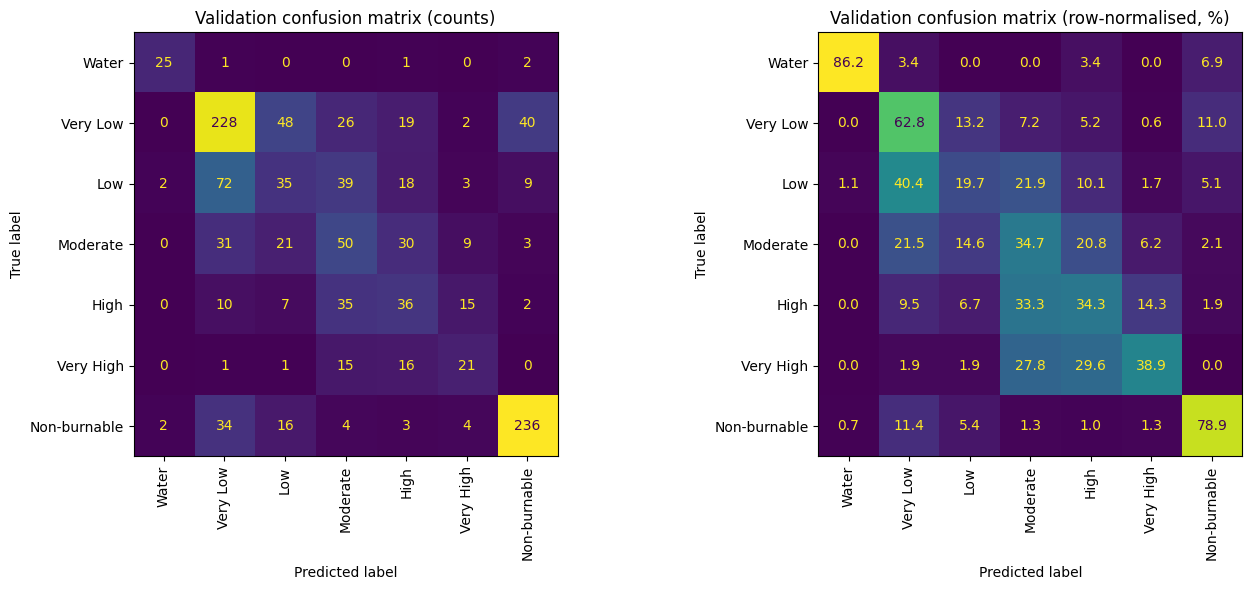

In [ ]:
val_probs, val_labels = predict_probs(customNet, val_set)
val_pred = val_probs.argmax(1)
labels_order = np.arange(NUM_CLASSES)
val_macro_f1 = f1_score(val_labels, val_pred, labels=labels_order, average='macro', zero_division=0)
print(f'Validation macro F1 = {val_macro_f1:.4f}\n')
print(classification_report(val_labels, val_pred, labels=labels_order, target_names=CLASS_NAMES,
                            digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cm_counts = confusion_matrix(val_labels, val_pred, labels=labels_order)
cm_rows = confusion_matrix(val_labels, val_pred, labels=labels_order, normalize='true')
ConfusionMatrixDisplay(cm_counts, display_labels=CLASS_NAMES).plot(ax=axes[0], xticks_rotation='vertical', colorbar=False)
ConfusionMatrixDisplay(100 * cm_rows, display_labels=CLASS_NAMES).plot(
    ax=axes[1], xticks_rotation='vertical', values_format='.1f', colorbar=False)
axes[0].set_title('Validation confusion matrix (counts)')
axes[1].set_title('Validation confusion matrix (row-normalised, %)')
plt.tight_layout()
plt.show()

In [ ]:
if final_history:
    curves = pd.DataFrame(final_history).set_index('epoch')
    best_epoch = int(curves['val_f1'].idxmax())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    curves[['train_loss', 'val_loss']].plot(ax=axes[0], title='Loss')
    curves[['train_f1', 'val_f1']].plot(ax=axes[1], title='Macro F1')
    for ax in axes:
        ax.axvline(best_epoch, color='gray', linestyle='--', label=f'best epoch ({best_epoch})')
        ax.set_xlabel('epoch')
        ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('No per-epoch history available for this checkpoint.')

No per-epoch history available for this checkpoint.


#### Test predictions

Softmax probabilities of the test split in `test_reduced.csv` order, class order 0 Water ... 6 Non-burnable, written to
`OUTPUT_DIR/output_custom.csv` without header (one row per image, seven columns).

In [ ]:
def check_probabilities(probabilities, n_rows):
    """Submission format checks: shape, finite values in [0, 1], rows summing to 1."""
    if probabilities.shape != (n_rows, NUM_CLASSES):
        raise ValueError(f'Expected shape {(n_rows, NUM_CLASSES)}, got {probabilities.shape}.')
    if not np.isfinite(probabilities).all():
        raise ValueError('Probabilities must be finite.')
    if (probabilities < 0).any() or (probabilities > 1).any():
        raise ValueError('Probabilities must lie in [0, 1].')
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5, rtol=0):
        raise ValueError('Each probability row must sum to 1.')


test_probs, _ = predict_probs(customNet, test_set)
check_probabilities(test_probs, len(test_set))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_csv = OUTPUT_DIR / 'output_custom.csv'
np.savetxt(output_csv, test_probs, delimiter=',', fmt='%.9g')
print(f'Saved {output_csv}: {test_probs.shape}, sha256 {sha256_of(output_csv)}')
print('Predicted class counts:', dict(zip(CLASS_NAMES, np.bincount(test_probs.argmax(1), minlength=NUM_CLASSES).tolist())))

Saved /kaggle/working/outputs/Lab_4_OUT/output_custom.csv: (1173, 7), sha256 c6288bf17d74dd876a022d371f719b77ece43f1d6798826dab1a4ee14c48b3cf
Predicted class counts: {'Water': 27, 'Very Low': 378, 'Low': 133, 'Moderate': 162, 'High': 116, 'Very High': 57, 'Non-burnable': 300}


#### Comparison with the submitted file

The SHA-256 of the new `output_custom.csv` is compared with the one of the submitted file stored in `ENTRY['reproduce']`
(no file is read). If it differs (different hardware or software), the predicted class counts and the validation macro F1
are compared with the submitted values in `ENTRY['expected']`.

In [ ]:
submission_check = None

if SMOKE_TEST:
    print('Comparison skipped (SMOKE_TEST).')
else:
    counts = np.bincount(test_probs.argmax(1), minlength=NUM_CLASSES)
    submission_check = dict(
        sha256_identical=sha256_of(output_csv, ignore_crlf=True) == REPRO['submitted_csv_sha256'],
        predicted_counts_abs_diff=int(np.abs(counts - np.array(ENTRY['expected']['predicted_counts'])).sum()),
        val_macro_f1_diff=abs(val_macro_f1 - ENTRY['expected']['val_macro_f1']))
    print(submission_check)
    if submission_check['sha256_identical']:
        print('IDENTICAL to the submission')
    else:
        print(f"Not bit-identical (different hardware/software): predicted counts differ by "
              f"{submission_check['predicted_counts_abs_diff']}, validation macro F1 by {submission_check['val_macro_f1_diff']:.4f}")

#### Run manifest

Everything needed to audit this run is saved in `OUTPUT_DIR/custom_run_manifest.json`: configuration, runtime flags,
library versions, seed, checkpoint and CSV hashes, validation F1 and the checks above.

In [ ]:
run_manifest = dict(
    created=datetime.now().isoformat(timespec='seconds'),
    trial_id=SELECTED, mode=FINAL_MODE, smoke_test=bool(SMOKE_TEST), epochs=FINAL_EPOCHS,
    config=FINAL_RUN, runtime_expected=RUNTIME, runtime_actual=runtime_now,
    seed=FINAL_RUN['seed'], val_macro_f1=float(val_macro_f1),
    checkpoint=str(used_ckpt), checkpoint_sha256=sha256_of(used_ckpt),
    output_csv=str(output_csv), output_csv_sha256=sha256_of(output_csv),
    reproducibility_check=repro_check, submission_check=submission_check,
    environment=dict(
        python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
        torchvision=torchvision.__version__, numpy=np.__version__, pandas=pd.__version__,
        cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
        gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'),
    history=final_history)
manifest_path = OUTPUT_DIR / 'custom_run_manifest.json'
manifest_path.write_text(json.dumps(run_manifest, indent=2))
print(f'Saved {manifest_path}')

Saved /kaggle/working/outputs/Lab_4_OUT/custom_run_manifest.json


## Part 4: Fine-tuning a pretrained network

Instead of training every weight from scratch, an ImageNet-pretrained torchvision network is adapted to the seven fire-risk classes:
- The last layer (1000 ImageNet classes) is replaced by a new, randomly initialised 7-output layer.
- **The whole network is updated** (no frozen layers), with a **discriminative learning rate**: backbone `lr`, new head `lr x head_mult`.
- Inputs are normalised with the ImageNet mean/std (already done in Part 1) and cropped to 224 x 224, the pretraining resolution.
- The fine-tuning search (section 4.3) and the final model (section 4.4) follow the same structure as Part 3.

### 4.1 Course reference: AlexNet

The course baseline: torchvision AlexNet, new last layer, 5 epochs of SGD with `StepLR`. It is kept as documentation and is not run
by default (`TRAIN_REFERENCE_FT = False`). AlexNet's `AdaptiveAvgPool2d((6, 6))` has no deterministic CUDA backward,
so strict determinism is switched off for this cell only. It reuses `criterion` and `dataloaders` from section 3.3.

In [ ]:
TRAIN_REFERENCE_FT = False
ALEXNET_EPOCHS = 5
ALEXNET_LR = 1e-3

if TRAIN_REFERENCE_FT:
    previous_strict = torch.are_deterministic_algorithms_enabled()
    set_determinism(False)
    seed_everything()
    alexNet = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
    alexNet.classifier[6] = nn.Linear(alexNet.classifier[6].in_features, NUM_CLASSES)
    alexNet = alexNet.to(device)
    optimizer_alex = optim.SGD(alexNet.parameters(), lr=ALEXNET_LR, momentum=0.9)
    scheduler_alex = lr_scheduler.StepLR(optimizer_alex, step_size=7, gamma=0.1)
    alexNet = train_model(alexNet, criterion, optimizer_alex, scheduler_alex, num_epochs=ALEXNET_EPOCHS)
    set_determinism(previous_strict)

### 4.2 Networks and adaptation

| Network | ImageNet weights | Head replaced | Parameters | Time per epoch (T4) |
|---|---|---|---|---|
| ConvNeXt-Tiny | `IMAGENET1K_V1` | `classifier[2]` | 27.8 M | 27.9 s |
| Swin-T | `IMAGENET1K_V1` | `head` | 27.6 M | 32.5 s |
| ResNet-50 | `IMAGENET1K_V2` | `fc` | 23.6 M | 22.0 s |
| EfficientNetV2-S (dropped) | `IMAGENET1K_V1` | `classifier[1]` | - | non-finite loss with AMP |

All weights come from ImageNet-1k. EfficientNetV2-S failed the compatibility test of section 4.3 and was replaced by ResNet-50.
Parameters and times are read from `search/ft/determinism_check.json`.

In [ ]:
FT_DIR = OUTPUT_DIR / 'ft'               # checkpoints written by this notebook (not versioned)
FT_SEARCH_DIR = SEARCH_DIR / 'ft'        # small CSV / JSON results of the fine-tuning search (versioned)
FT_NUM_WORKERS = 4                       # as in the original run: the random-crop streams depend on the worker count
if os.name == 'nt' and FT_NUM_WORKERS > 0:   # notebook-defined classes cannot be pickled by spawned Windows workers
    print(f'Windows: fine-tuning workers {FT_NUM_WORKERS} -> 0 (the random crops differ from the original run).')
    FT_NUM_WORKERS = 0

# lr = range of the BACKBONE learning rate (log-uniform); the new 7-class head gets lr * head_mult.
# sd = default stochastic-depth probability of the torchvision model (rescaled to the sampled drop_path).
ARCH_SPECS = {
    'convnext_tiny':     dict(short='cnx', builder=models.convnext_tiny,
                              weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1, lr=(2e-5, 3e-4), sd=0.1),
    'efficientnet_v2_s': dict(short='eff', builder=models.efficientnet_v2_s,
                              weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1, lr=(5e-5, 8e-4), sd=0.2),
    'swin_t':            dict(short='swin', builder=models.swin_t,
                              weights=models.Swin_T_Weights.IMAGENET1K_V1, lr=(2e-5, 3e-4), sd=0.2),
    'resnet50':          dict(short='r50', builder=models.resnet50,
                              weights=models.ResNet50_Weights.IMAGENET1K_V2, lr=(5e-5, 8e-4), sd=None),
}
FT_ARCHS = ['convnext_tiny', 'efficientnet_v2_s', 'swin_t']   # searched architectures
FT_RESERVE = ['resnet50']                                     # replaces an architecture that fails the compatibility test
FT_NO_DECAY_KEYS = ('relative_position_bias_table', 'layer_scale')


def replace_adaptive_pools(module):
    """Swap every AdaptiveAvgPool2d(1) (final pooling, squeeze-excitation blocks) for the deterministic GlobalAvgPool of Part 2."""
    for name, child in module.named_children():
        if isinstance(child, nn.AdaptiveAvgPool2d) and child.output_size in (1, (1, 1)):
            setattr(module, name, GlobalAvgPool())
        else:
            replace_adaptive_pools(child)
    return module


def make_model(arch, drop_path, pretrained=True):
    """Torchvision model with a NEW 7-output layer. Returns (model, head).

    `pretrained=False` skips the ImageNet weights (no download): used to load a checkpoint and in smoke tests."""
    spec = ARCH_SPECS[arch]
    m = spec['builder'](weights=spec['weights'] if pretrained else None)
    if arch == 'convnext_tiny':
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, NUM_CLASSES)
        head = m.classifier
    elif arch == 'efficientnet_v2_s':
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        head = m.classifier
    elif arch == 'swin_t':
        m.head = nn.Linear(m.head.in_features, NUM_CLASSES)
        head = m.head
    elif arch == 'resnet50':
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        head = m.fc
    else:
        raise ValueError(arch)
    if spec['sd']:   # keep the per-block linear schedule of torchvision, scaled to the requested maximum
        for module in m.modules():
            if isinstance(module, StochasticDepth):
                module.p = module.p * drop_path / spec['sd']
    return replace_adaptive_pools(m), head


def param_groups(model, head, lr, head_mult, wd):
    """Backbone vs new head (head lr = lr * head_mult); no weight decay on biases, norms and layer-scale."""
    head_ids = {id(p) for p in head.parameters()}
    groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        part = 'head' if id(p) in head_ids else 'backbone'
        decay = p.ndim > 1 and not any(k in name for k in FT_NO_DECAY_KEYS)
        groups.setdefault((part, decay), []).append(p)
    return [{'params': ps, 'lr': lr * (head_mult if part == 'head' else 1), 'weight_decay': wd if decay else 0.0}
            for (part, decay), ps in groups.items()]


def build_ft(cfg, epochs, pretrained=True, num_workers=None):
    """Model, loss, optimiser, scheduler and loaders of one fine-tuning configuration (seed 42 everywhere).

    Same schedule as `build_run`: AdamW, linear warm-up then cosine decay, stepped once per epoch."""
    workers = FT_NUM_WORKERS if num_workers is None else num_workers
    seed_everything(SEED)
    model, head = make_model(cfg['arch'], cfg['drop_path'], pretrained)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weight_tensor(cfg['class_weights']),
                                    label_smoothing=cfg['label_smoothing'])
    optimizer = optim.AdamW(param_groups(model, head, cfg['lr'], cfg['head_mult'], cfg['weight_decay']), lr=cfg['lr'])
    w = cfg['warmup_epochs']
    scheduler = lr_scheduler.LambdaLR(optimizer, lambda e: (e + 1) / (w + 1) if e < w else
                                      0.5 * (1 + math.cos(math.pi * (e - w) / max(1, epochs - w))))
    train_loader = DataLoader(train_dataset, batch_size=cfg['batch_size'], shuffle=True, num_workers=workers,
                              worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(SEED),
                              pin_memory=PIN_MEMORY, persistent_workers=workers > 0)
    val_loader = DataLoader(eval_ds('val', cfg.get('eval_size', 224)), batch_size=64, shuffle=False, num_workers=workers, pin_memory=PIN_MEMORY)
    loaders = {'train': GPULoader(train_loader, GPUAugment(PIXEL_MEAN, PIXEL_STD, **AUG_PRESETS[cfg['aug']])),
               'val': val_loader}
    return model, criterion, optimizer, scheduler, loaders

### 4.3 Fine-tuning hyper-parameter search (documented, not re-run)

The search ran **once on a Kaggle T4** (strict determinism, 4 workers, AMP, seed 42) in two phases; results are read from
`search/ft/`, which the no-dependencies version does not include (the display cells only print a notice). With `RUN_SEARCH = False` (Part 1) every execution cell below is skipped.
- **Phase 1:** 10 configurations per network, 10 epochs, median-stopping pruning after epoch 4 against finished trials of the same network (at least 3). Trial `00` is the standard recipe.
- **Phase 2:** the 2 best phase-1 configurations of each network, retrained for 30 epochs without pruning; the best-epoch weights are saved.
- **Compatibility test:** each network, standard recipe, 1 epoch trained twice: weights must be identical (also measures s/epoch).

| Group | Hyper-parameter | Explored values |
|---|---|---|
| Architecture | network | ConvNeXt-Tiny, Swin-T, ResNet-50 (EfficientNetV2-S dropped) |
| Architecture | `drop_path` (stochastic depth, max value; ResNet-50 has none) | 0.1, 0.2, 0.3 |
| Training | backbone `lr` | log-uniform: ConvNeXt, Swin [2e-5, 3e-4]; ResNet-50 [5e-5, 8e-4] |
| Training | `head_mult` (head lr = lr x head_mult) | 1, 10 |
| Training | `weight_decay` | log-uniform [0.01, 0.1] |
| Training | `batch_size`, `warmup_epochs` | 32, 64; 1, 2 |
| Training | `label_smoothing`, `class_weights` | 0, 0.1; `none`, `sqrt_inv` |
| Training | `mixup_alpha`, `aug` | 0 (probability 2/3), 0.2; `light`, `strong` |

Fixed: AdamW, cosine decay after warm-up, AMP, 224 crop, ImageNet normalisation. Trial `00` of each network uses the geometric mean of
its lr range, `head_mult` 10, weight decay 0.05, batch 32, 1 warm-up epoch, label smoothing 0.1, `sqrt_inv`, no mixup, `strong`, `drop_path` 0.1.

In [ ]:
FT_N_PHASE1 = 10               # random configurations per network (phase 1)
FT_P1_EPOCHS = 10              # epochs per phase-1 trial
FT_P1_PRUNE_AT = 4             # median stopping after this epoch
FT_P1_MIN_FOR_PRUNE = 3        # finished trials of the same network needed before pruning
FT_N_FINALISTS = 2             # phase 2: best configurations of each network, retrained longer
FT_P2_EPOCHS = 30
FT_MAX_HOURS = 11.0            # Kaggle kills a commit run at 12 h; nothing starts that would not finish before this
FT_RESERVE_MIN = 10            # minutes kept for the final predictions
FT_SEARCH_AMP = device.type == 'cuda'

FT_RESULT_COLS = ['trial_id', 'phase', 'arch', 'status', 'best_val_f1', 'best_epoch', 'last5_val_f1', 'epochs_run',
                  'train_f1_at_best', 'minutes', 'val_f1_history', 'cfg']
FT_ARCH_KEYS = ['arch', 'drop_path']
FT_TRAIN_KEYS = ['lr', 'head_mult', 'weight_decay', 'batch_size', 'warmup_epochs', 'label_smoothing',
                 'class_weights', 'mixup_alpha', 'aug']


def ft_default_cfg(arch):
    """The standard fine-tuning recipe: always trial 00 of each network."""
    lo, hi = ARCH_SPECS[arch]['lr']
    return dict(arch=arch, lr=_round3(math.sqrt(lo * hi)), head_mult=10, weight_decay=0.05, batch_size=32,
                warmup_epochs=1, label_smoothing=0.1, class_weights='sqrt_inv', mixup_alpha=0.0, aug='strong',
                drop_path=0.1)


def ft_sample_configs(arch, n):
    """Deterministic random search (string seed: the same list on every machine and run)."""
    rng = random.Random(f'ft-{arch}-{SEED}')
    lo, hi = ARCH_SPECS[arch]['lr']
    short = ARCH_SPECS[arch]['short']
    configs = [{**ft_default_cfg(arch), 'trial_id': f'{short}_p1_00'}]
    for i in range(1, n):
        configs.append(dict(arch=arch,
                            lr=_round3(_loguniform(rng, lo, hi)),
                            head_mult=rng.choice([1, 10]),
                            weight_decay=_round3(_loguniform(rng, 0.01, 0.1)),
                            batch_size=rng.choice([32, 64]),
                            warmup_epochs=rng.choice([1, 2]),
                            label_smoothing=rng.choice([0.0, 0.1]),
                            class_weights=rng.choice(['none', 'sqrt_inv']),
                            mixup_alpha=rng.choice([0.0, 0.0, 0.2]),
                            aug=rng.choice(['light', 'strong']),
                            drop_path=rng.choice([0.1, 0.2, 0.3]),
                            trial_id=f'{short}_p1_{i:02d}'))
    return configs


def ft_read_results():
    path = FT_SEARCH_DIR / 'ft_results.csv'
    return pd.read_csv(path) if path.exists() else pd.DataFrame(columns=FT_RESULT_COLS)


def ft_leaderboard(phase=None):
    """Trials (optionally one phase) with their hyper-parameters, best validation macro F1 first."""
    r = ft_read_results()
    if phase:
        r = r[r['phase'] == phase]
    if r.empty:
        return r
    cfgs = pd.DataFrame([json.loads(c) for c in r['cfg']]).drop(columns=['trial_id', 'arch'], errors='ignore')
    out = pd.concat([r.drop(columns=['val_f1_history', 'cfg']).reset_index(drop=True), cfgs], axis=1)
    return out.sort_values('best_val_f1', ascending=False).reset_index(drop=True)


def ft_predict(model, dataset):
    """Softmax probabilities (float64) and labels in dataset order: fp32, batch 64, no augmentation, as in the original run."""
    return predict_probs(model, dataset, batch_size=64, dtype=np.float64)

In [ ]:
def ft_weights_of(model):
    return {k: v.detach().float().cpu().clone() for k, v in model.state_dict().items()}


def ft_minutes_left():
    return FT_MAX_HOURS * 60 - (time.time() - FT_T0) / 60


def ft_est_minutes(arch, epochs):
    return 1.15 * epochs * FT_SEC_PER_EPOCH[arch] / 60 + 1


def ft_run_trial(cfg, phase, epochs, prune):
    """Train one configuration; stores its per-epoch CSV and one row of ft_results.csv. Returns (model, row)."""
    since = time.time()
    model, criterion, optimizer, scheduler, loaders = build_ft(cfg, epochs)
    previous = ft_read_results()
    finished = [json.loads(h) for h in previous[(previous['phase'] == phase) & (previous['arch'] == cfg['arch']) &
                                                (previous['status'].isin(['done', 'pruned']))]['val_f1_history']]
    log = []

    def stop_early(info):
        log.append({'epoch': info['epoch'] + 1, 'train_loss': info['train_loss'], 'train_f1': info['train_f1'],
                    'val_loss': info['val_loss'], 'val_f1': info['val_f1'], 'lr': optimizer.param_groups[0]['lr']})
        e = len(log)
        if prune and e == FT_P1_PRUNE_AT:
            reference = [max(h[:e]) for h in finished if len(h) >= e]
            best = max(r['val_f1'] for r in log)
            if len(reference) >= FT_P1_MIN_FOR_PRUNE and best < statistics.median(reference):
                print(f'Pruning: best val F1 {best:.3f} after {e} epochs < median {statistics.median(reference):.3f}')
                return True
        return False

    model = train_model(model, criterion, optimizer, scheduler, num_epochs=epochs, plot_confusion_matrix=False,
                        loaders=loaders, amp=FT_SEARCH_AMP, mixup_alpha=cfg['mixup_alpha'],
                        epoch_callback=stop_early, verbose=False, mix_prob=1.0)
    table = pd.DataFrame(log)
    table.to_csv(FT_SEARCH_DIR / f"{cfg['trial_id']}_epochs.csv", index=False)
    history = table['val_f1'].tolist()
    b = int(np.argmax(history))
    row = dict(trial_id=cfg['trial_id'], phase=phase, arch=cfg['arch'],
               status='pruned' if len(history) < epochs else 'done', best_val_f1=round(history[b], 4), best_epoch=b + 1,
               last5_val_f1=round(float(np.mean(history[-5:])), 4), epochs_run=len(history),
               train_f1_at_best=round(float(table['train_f1'][b]), 4), minutes=round((time.time() - since) / 60, 2),
               val_f1_history=json.dumps([round(float(h), 4) for h in history]), cfg=json.dumps(cfg))
    results_csv = FT_SEARCH_DIR / 'ft_results.csv'
    pd.DataFrame([row], columns=FT_RESULT_COLS).to_csv(results_csv, mode='a', header=not results_csv.exists(), index=False)
    FT_SEC_PER_EPOCH[cfg['arch']] = max(FT_SEC_PER_EPOCH[cfg['arch']], 60 * row['minutes'] / max(1, len(history)))
    return model, row


def ft_per_class_row(name, model):
    """Append the per-class validation F1 of a trained model (fp32 reload) to ft_per_class_f1.csv."""
    probabilities, labels = ft_predict(model, val_dataset)
    pc = f1_score(labels, probabilities.argmax(1), labels=np.arange(NUM_CLASSES), average=None, zero_division=0)
    path = FT_SEARCH_DIR / 'ft_per_class_f1.csv'
    pd.DataFrame([[name, *pc, pc.mean()]], columns=['trial_id', *CLASS_NAMES, 'macro_fp32']).to_csv(
        path, mode='a', header=not path.exists(), index=False)
    return pc.mean()

#### Compatibility and determinism test

In [ ]:
if RUN_SEARCH:
    set_determinism(True)
    FT_T0 = time.time()
    FT_DIR.mkdir(parents=True, exist_ok=True)
    FT_SEARCH_DIR.mkdir(parents=True, exist_ok=True)
    for arch in FT_ARCHS + FT_RESERVE:   # download the ImageNet weights now (needs Internet)
        ARCH_SPECS[arch]['weights'].get_state_dict(progress=False)

    det_file = FT_SEARCH_DIR / 'determinism_check.json'
    det = json.loads(det_file.read_text()) if det_file.exists() else {}
    reserve, checked, queue = list(FT_RESERVE), [], list(FT_ARCHS)
    while queue:
        arch = queue.pop(0)
        if arch not in det:
            try:
                states, secs = [], []
                for _ in range(2):
                    m, crit, opt, sch, ld = build_ft(ft_default_cfg(arch), 1)
                    t = time.time()
                    m = train_model(m, crit, opt, sch, num_epochs=1, plot_confusion_matrix=False, loaders=ld,
                                    amp=FT_SEARCH_AMP, mixup_alpha=0.0, verbose=False, mix_prob=1.0)
                    secs.append(time.time() - t)
                    states.append(ft_weights_of(m))
                    del m, opt
                    free_memory()
                diff = max((states[0][k] - states[1][k]).abs().max().item() for k in states[0])
                det[arch] = {'max_abs_weight_diff': diff, 'identical': diff == 0.0, 'sec_per_epoch': min(secs),
                             'params': sum(v.numel() for v in states[0].values())}
                del states
            except Exception as e:
                det[arch] = {'error': repr(e)}
                free_memory()
            det_file.write_text(json.dumps({**det, 'torch': torch.__version__, 'torchvision': torchvision.__version__,
                                            'cuda': torch.version.cuda}, indent=1))
        print(arch, det[arch])
        if 'error' in det[arch] or not det[arch].get('identical', False):
            if reserve:
                substitute = reserve.pop(0)
                print(f'  -> {arch} is not usable or not deterministic here: replaced by {substitute}')
                queue.insert(0, substitute)
            continue
        checked.append(arch)

    FT_ARCHS = checked
    FT_SEC_PER_EPOCH = {a: det[a]['sec_per_epoch'] for a in FT_ARCHS}
    p1_minutes = sum(FT_N_PHASE1 * FT_P1_EPOCHS * FT_SEC_PER_EPOCH[a] for a in FT_ARCHS) / 60
    p2_minutes = sum(FT_N_FINALISTS * FT_P2_EPOCHS * FT_SEC_PER_EPOCH[a] for a in FT_ARCHS) / 60
    print(f'Architectures in the search: {FT_ARCHS}. Estimated: phase 1 <= {p1_minutes:.0f} min, phase 2 {p2_minutes:.0f} min')

In [ ]:
det_path = FT_SEARCH_DIR / 'determinism_check.json'
if det_path.exists():
    det_stored = json.loads(det_path.read_text())
    rows = {a: v for a, v in det_stored.items() if isinstance(v, dict)}
    display(pd.DataFrame(rows).T)
    print(f"torch {det_stored.get('torch')}, torchvision {det_stored.get('torchvision')}, CUDA {det_stored.get('cuda')}")
else:
    print(NO_SEARCH_MSG)

### Phase 1 - 10 random configurations per network

The search is round-robin over the networks, so all of them are covered even if time runs short.

In [ ]:
if RUN_SEARCH:
    FT_PHASE1 = {a: ft_sample_configs(a, FT_N_PHASE1) for a in FT_ARCHS}
    done_ids = set(ft_read_results()['trial_id'])
    for i in range(FT_N_PHASE1):
        for arch in FT_ARCHS:
            cfg = FT_PHASE1[arch][i]
            if cfg['trial_id'] in done_ids:
                continue
            phase2_need = sum(ft_est_minutes(a, FT_P2_EPOCHS) * FT_N_FINALISTS for a in FT_ARCHS)
            if ft_est_minutes(arch, FT_P1_EPOCHS) + phase2_need + FT_RESERVE_MIN > ft_minutes_left():
                print(f"{cfg['trial_id']}: skipped (time is reserved for phase 2)")
                continue
            print(f"\n##### PHASE 1 {cfg['trial_id']} | {(time.time() - FT_T0) / 60:.0f} min elapsed | {cfg}")
            try:
                model, row = ft_run_trial(cfg, 'p1', FT_P1_EPOCHS, prune=True)
                print(f"=== {row['trial_id']}: best {row['best_val_f1']:.4f} (epoch {row['best_epoch']}) {row['status']}")
                del model
            except torch.cuda.OutOfMemoryError:
                print('CUDA out of memory -> trial skipped')
            except Exception as e:
                print(f"{cfg['trial_id']}: FAILED with {e!r}")
            free_memory()
    ft_leaderboard('p1').round(4).to_csv(FT_SEARCH_DIR / 'ft_leaderboard_phase1.csv', index=False)

In [ ]:
def show_ft_leaderboard(phase, top=10):
    """Top trials of a phase with their architecture and training hyper-parameters (read from ft_results.csv)."""
    board = ft_leaderboard(phase)
    if board.empty:
        print(NO_SEARCH_MSG)
        return
    keys = ['trial_id', 'status', 'best_val_f1', 'best_epoch', 'last5_val_f1', 'epochs_run', 'train_f1_at_best']
    board = board[keys + [k for k in FT_ARCH_KEYS[1:] + FT_TRAIN_KEYS if k in board]].copy()
    board.insert(1, 'arch', board['trial_id'].str.split('_').str[0])
    board['lr'] = board['lr'].map('{:.3g}'.format)
    display(board.head(top).round(4))


ft_phase1 = ft_leaderboard('p1')
if not ft_phase1.empty:
    ft_phase1 = ft_phase1.assign(network=ft_phase1['trial_id'].str.split('_').str[0])
    summary = ft_phase1.groupby('network').agg(
        trials=('trial_id', 'size'), pruned=('status', lambda s: int((s == 'pruned').sum())),
        best_val_f1=('best_val_f1', 'max'))
    summary['mean_val_f1_of_done'] = ft_phase1[ft_phase1['status'] == 'done'].groupby('network')['best_val_f1'].mean()
    display(summary.round(4))
show_ft_leaderboard('p1', top=10)

### Phase 2 - the two best configurations of each network, 30 epochs

The checkpoint of the best validation epoch is stored in `FT_DIR` as `<trial_id>.pt`, and the per-class validation F1 of the
reloaded fp32 model in `ft_per_class_f1.csv`.

In [ ]:
if RUN_SEARCH:
    board1 = ft_leaderboard('p1')
    finalists = []
    for rank in range(FT_N_FINALISTS):
        for arch in FT_ARCHS:
            sub = board1[(board1['arch'] == arch) & (board1['status'].isin(['done', 'pruned']))]
            if len(sub) > rank:
                parent = sub.iloc[rank]['trial_id']
                cfg = json.loads(ft_read_results().set_index('trial_id').loc[parent, 'cfg'])
                cfg.update(trial_id=f"{ARCH_SPECS[arch]['short']}_p2_{rank}", parent=parent)
                finalists.append(cfg)

    done_ids = set(ft_read_results()['trial_id'])
    for cfg in finalists:
        if cfg['trial_id'] in done_ids and (FT_DIR / f"{cfg['trial_id']}.pt").exists():
            continue
        if ft_est_minutes(cfg['arch'], FT_P2_EPOCHS) + FT_RESERVE_MIN > ft_minutes_left():
            print(f"{cfg['trial_id']}: skipped, not enough time left")
            continue
        print(f"\n##### PHASE 2 {cfg['trial_id']} (from {cfg['parent']}) | {(time.time() - FT_T0) / 60:.0f} min elapsed")
        try:
            model, row = ft_run_trial(cfg, 'p2', FT_P2_EPOCHS, prune=False)
            torch.save({'state_dict': model.state_dict(), 'cfg': cfg, 'best_val_f1_amp': row['best_val_f1'],
                        'best_epoch': row['best_epoch']}, FT_DIR / f"{cfg['trial_id']}.pt")
            f32 = ft_per_class_row(cfg['trial_id'], model)
            print(f"=== {row['trial_id']}: best {row['best_val_f1']:.4f} (epoch {row['best_epoch']}), "
                  f"fp32 reload {f32:.4f}, {row['minutes']:.0f} min")
            del model
        except torch.cuda.OutOfMemoryError:
            print('CUDA out of memory -> run skipped')
        except Exception as e:
            print(f"{cfg['trial_id']}: FAILED with {e!r}")
        free_memory()
    ft_leaderboard('p2').round(4).to_csv(FT_SEARCH_DIR / 'ft_leaderboard_phase2.csv', index=False)

In [ ]:
show_ft_leaderboard('p2')

ft_phase2 = ft_leaderboard('p2')
if not ft_phase2.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    for trial in ft_phase2['trial_id']:
        epochs_csv = FT_SEARCH_DIR / f'{trial}_epochs.csv'
        if epochs_csv.exists():
            curve = pd.read_csv(epochs_csv)
            ax.plot(curve['epoch'], curve['val_f1'], label=trial)
    ax.set_xlabel('epoch')
    ax.set_ylabel('validation macro F1')
    ax.set_title('Phase 2: validation macro F1 per epoch')
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

per_class_path = FT_SEARCH_DIR / 'ft_per_class_f1.csv'
if per_class_path.exists():
    display(pd.read_csv(per_class_path).set_index('trial_id').round(3))

No fine-tuning results found in /kaggle/working/search/ft


### Findings

Metric: best validation macro F1 (single seed, the validation split also chose the checkpoint, so values are slightly optimistic).
- Every network reaches 0.50-0.54 in 10 epochs (phase 1): pretrained features are far better than the best custom CNN (0.496).
- Phase 2 ranking: **Swin-T `swin_p2_1` 0.546** (epoch 26), ResNet-50 `r50_p2_0` 0.539, Swin-T `swin_p2_0` 0.532; ConvNeXt-Tiny peaked early (0.505, 0.501).
- The top three differ by less than the seed noise measured in section 3.4 (about 0.008 to 0.015): their order is not conclusive.
- 11 of the 30 phase-1 trials were pruned, mostly ResNet-50 (6); EfficientNetV2-S was excluded by the compatibility test (non-finite loss with AMP).

### 4.4 Final fine-tuned model and reproducibility

No-dependencies version: the settings of the selected model are written in the next cell; `final/ft_final_config.json` is not read. They are used by `build_ft`, the train-or-load cell (`FT_MODE`) and the comparison with the submission.
`USE_CHECKPOINTS = False` retrains it (needs Internet once to download the ImageNet weights of Swin-T from torchvision); `True` loads `CHECKPOINT_DIR / ft_final_swin_p2_1.pt`.
Strict determinism is switched on for this section and restored at its end. Retraining is bit-exact only on a Tesla T4
with 4 workers (Linux / Kaggle); on Windows the workers are forced to 0.

In [ ]:
FT_SELECTED = 'swin_p2_1'
FT_ENTRY = dict(
    arch=dict(arch='swin_t', drop_path=0.2, eval_size=224, predict_size=FT_PREDICT_SIZE),
    train=dict(lr=2.37e-05, head_mult=1, weight_decay=0.0395, batch_size=32, warmup_epochs=2, label_smoothing=0.0,
               class_weights='sqrt_inv', mixup_alpha=0.0, aug='light', epochs=30),
    runtime=dict(num_workers=4, strict_determinism=True, amp=True),
    reproduce=dict(checkpoint='ft_final_swin_p2_1.pt',
                   checkpoint_sha256='761fc21d43e443ca4799039e385802b7f2e8fa1a4dc7a0117eebacd408d123ac',
                   submitted_csv_sha256='9055d95d0fd61035ae8a6a07d7283a62eb5261a74c25b8258a8d8401197c12f7'),
    expected=dict(val_macro_f1=0.5177071786161177, best_val_f1_training=0.5457, best_epoch=26,
                  predicted_counts=[24, 366, 172, 146, 94, 60, 311]))

FT_REPRO = FT_ENTRY['reproduce']
FT_RUNTIME = FT_ENTRY['runtime']
FT_MEMBERS = [FT_SELECTED]
FT_MODE = 'retrain' if SMOKE_TEST or not USE_CHECKPOINTS else 'checkpoint'
FT_RUN = {**FT_ENTRY['arch'], **FT_ENTRY['train'], 'trial_id': FT_SELECTED}   # flat configuration for `build_ft`

FT_WORKERS = FT_RUNTIME['num_workers']
if os.name == 'nt' and FT_WORKERS > 0:
    FT_WORKERS = 0
FT_PREVIOUS_STRICT = torch.are_deterministic_algorithms_enabled()
set_determinism(FT_RUNTIME['strict_determinism'])
print(f"Final fine-tuned model {FT_SELECTED} ({FT_RUN['arch']}): mode {FT_MODE}, workers {FT_WORKERS}")

ft_runtime_now = dict(num_workers=FT_WORKERS, strict_determinism=torch.are_deterministic_algorithms_enabled())
ft_runtime_diff = {k: (ft_runtime_now[k], FT_RUNTIME[k]) for k in ft_runtime_now if ft_runtime_now[k] != FT_RUNTIME[k]}
if ft_runtime_diff and not SMOKE_TEST:
    print('WARNING: runtime differs from the configuration (current, expected):', ft_runtime_diff)

#### Train or load

Both paths fill `ft_models` (best-validation-F1 weights, evaluation mode) and `ft_histories` (per-epoch metrics, empty when a
checkpoint is loaded) with one entry per member (here only the selected network). `ftNet` is the first member.

In [ ]:
def ft_load_checkpoint(path):
    """Network (evaluation mode, on `device`) stored in a checkpoint written by the search or by this section."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model, _ = make_model(checkpoint['cfg']['arch'], checkpoint['cfg']['drop_path'], pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(device).eval()


ft_models, ft_histories, ft_ckpts = {}, {}, {}
for member in FT_MEMBERS:
    run = FT_RUN
    if FT_MODE == 'retrain':
        epochs = 1 if SMOKE_TEST else run['epochs']
        history = []
        model, criterion_ft, optimizer_ft, scheduler_ft, loaders_ft = build_ft(
            run, epochs, pretrained=not SMOKE_TEST, num_workers=FT_WORKERS)
        model = train_model(model, criterion_ft, optimizer_ft, scheduler_ft, num_epochs=epochs,
                            plot_confusion_matrix=False, loaders=loaders_ft, amp=FT_RUNTIME['amp'],
                            mixup_alpha=run['mixup_alpha'], verbose=False, history=history, mix_prob=1.0)
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        ft_ckpts[member] = OUTPUT_DIR / f'{member}_retrained.pt'
        torch.save({'state_dict': model.state_dict(), 'cfg': run}, ft_ckpts[member])
        ft_models[member], ft_histories[member] = model, history
        del criterion_ft, optimizer_ft, scheduler_ft, loaders_ft
    else:
        ft_ckpts[member] = find_checkpoint(FT_REPRO['checkpoint'])
        if ft_ckpts[member] is None:
            raise FileNotFoundError(
                f"Checkpoint '{FT_REPRO['checkpoint']}' not found. Place it in {CHECKPOINT_DIR.resolve()} or set "
                f'USE_CHECKPOINTS = False to train {member} from scratch.')
        ft_models[member] = ft_load_checkpoint(ft_ckpts[member])
        ft_histories[member] = []
    free_memory()

ftNet = ft_models[FT_MEMBERS[0]]
for member in FT_MEMBERS:
    print(f'{member} ({FT_MODE}): {sum(p.numel() for p in ft_models[member].parameters()):,} parameters, '
          f'weights from {ft_ckpts[member]}')

#### Reproducibility check

Same checks as in section 3.5: in checkpoint mode the file hash is compared with `FT_ENTRY['reproduce']`; after a retraining, the
best epoch and its validation F1 (training log, validation at 224) are compared with the original run and, if the original
checkpoint file exists, both networks are compared: largest absolute difference over all weights and over the validation
probabilities. A weight difference of exactly 0 means the run is bit-exact.

In [ ]:
ft_repro_checks = {}
for member in FT_MEMBERS:
    reference = find_checkpoint(FT_REPRO['checkpoint'])
    if FT_MODE == 'checkpoint':
        ft_repro_checks[member] = dict(
            checkpoint_sha256_matches_config=sha256_of(ft_ckpts[member]) == FT_REPRO['checkpoint_sha256'])
    elif not SMOKE_TEST:
        best = max(ft_histories[member], key=lambda row: row['val_f1'])   # validation at 224 during training
        ft_repro_checks[member] = dict(
            best_epoch=int(best['epoch']), expected_best_epoch=FT_ENTRY['expected']['best_epoch'],
            best_val_f1=round(float(best['val_f1']), 4), expected_best_val_f1=FT_ENTRY['expected']['best_val_f1_training'])
        if reference is not None:
            reference_net = ft_load_checkpoint(reference)
            weight_diff = max(float((a.float() - b.float()).abs().max())
                              for a, b in zip(ft_models[member].state_dict().values(), reference_net.state_dict().values()))
            p_new, _ = ft_predict(ft_models[member], val_dataset)
            p_ref, _ = ft_predict(reference_net, val_dataset)
            ft_repro_checks[member].update(reference=str(reference), max_abs_weight_diff=weight_diff,
                                           max_abs_prob_diff=float(np.abs(p_new - p_ref).max()),
                                           same_argmax_pct=float(100 * (p_new.argmax(1) == p_ref.argmax(1)).mean()))
            del reference_net
    print(member, ft_repro_checks.get(member, 'check skipped (SMOKE_TEST)'))

#### Validation report

Macro F1 and per-class precision / recall / F1 on the validation split, the confusion matrix with counts and
row-normalised (rows = true class, columns = predicted class), and the learning curves of each member.
The validation split chose the checkpoint, so its F1 is slightly optimistic with respect to the test set.

In [ ]:
def ft_probs(dataset):
    """Probabilities of the selected model, float64 (mean over the members of an ensemble), rows renormalised."""
    member_probs = [ft_predict(ft_models[m], dataset)[0] for m in FT_MEMBERS]
    probabilities = np.mean(member_probs, axis=0) if len(member_probs) > 1 else member_probs[0]
    return probabilities / probabilities.sum(axis=1, keepdims=True)


ft_val_labels = val_dataset.dataset['label'].to_numpy()
ft_val_probs = ft_probs(eval_ds('val', FT_PREDICT_SIZE))
ft_val_pred = ft_val_probs.argmax(1)
ft_val_macro_f1 = f1_score(ft_val_labels, ft_val_pred, labels=np.arange(NUM_CLASSES), average='macro', zero_division=0)
print(f'Validation macro F1 = {ft_val_macro_f1:.4f}\n')
print(classification_report(ft_val_labels, ft_val_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
                            digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ft_cm_counts = confusion_matrix(ft_val_labels, ft_val_pred, labels=np.arange(NUM_CLASSES))
ft_cm_rows = confusion_matrix(ft_val_labels, ft_val_pred, labels=np.arange(NUM_CLASSES), normalize='true')
ConfusionMatrixDisplay(ft_cm_counts, display_labels=CLASS_NAMES).plot(ax=axes[0], xticks_rotation='vertical', colorbar=False)
ConfusionMatrixDisplay(100 * ft_cm_rows, display_labels=CLASS_NAMES).plot(
    ax=axes[1], xticks_rotation='vertical', values_format='.1f', colorbar=False)
axes[0].set_title('Validation confusion matrix (counts)')
axes[1].set_title('Validation confusion matrix (row-normalised, %)')
plt.tight_layout()
plt.show()

In [ ]:
for member, history in ft_histories.items():
    if not history:
        print(f'{member}: no per-epoch history available for this checkpoint.')
        continue
    curves = pd.DataFrame(history).set_index('epoch')
    best_epoch = int(curves['val_f1'].idxmax())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    curves[['train_loss', 'val_loss']].plot(ax=axes[0], title=f'{member}: loss')
    curves[['train_f1', 'val_f1']].plot(ax=axes[1], title=f'{member}: macro F1')
    for ax in axes:
        ax.axvline(best_epoch, color='gray', linestyle='--', label=f'best epoch ({best_epoch})')
        ax.set_xlabel('epoch')
        ax.legend()
    plt.tight_layout()
    plt.show()

swin_p2_1: no per-epoch history available for this checkpoint.


#### Test predictions

Softmax probabilities of the test split in `test_reduced.csv` order (fp32, centre crop, no test-time augmentation),
written to `OUTPUT_DIR/output_ft.csv` without header, seven columns, with the same writer (`%.9g`) as the original run.

In [ ]:
ft_test_probs = ft_probs(eval_ds('test', FT_PREDICT_SIZE))
check_probabilities(ft_test_probs, len(test_dataset))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ft_output_csv = OUTPUT_DIR / 'output_ft.csv'
np.savetxt(ft_output_csv, ft_test_probs, delimiter=',', fmt='%.9g')
print(f'Saved {ft_output_csv}: {ft_test_probs.shape}, sha256 {sha256_of(ft_output_csv, ignore_crlf=True)}')
print('Predicted class counts:', dict(zip(CLASS_NAMES, np.bincount(ft_test_probs.argmax(1), minlength=NUM_CLASSES).tolist())))

Saved /kaggle/working/outputs/Lab_4_OUT/output_ft.csv: (1173, 7), sha256 9055d95d0fd61035ae8a6a07d7283a62eb5261a74c25b8258a8d8401197c12f7
Predicted class counts: {'Water': 24, 'Very Low': 366, 'Low': 172, 'Moderate': 146, 'High': 94, 'Very High': 60, 'Non-burnable': 311}


#### Comparison with the submitted file

The SHA-256 of the new `output_ft.csv` is compared with the one of the submitted file stored in `FT_ENTRY['reproduce']`
(no file is read). If it differs (attention kernels differ slightly between GPU models), the predicted class counts and the
validation macro F1 are compared with the submitted values in `FT_ENTRY['expected']`.

In [ ]:
ft_submission_check = None

if SMOKE_TEST:
    print('Comparison skipped (SMOKE_TEST).')
else:
    ft_counts = np.bincount(ft_test_probs.argmax(1), minlength=NUM_CLASSES)
    ft_submission_check = dict(
        sha256_identical=sha256_of(ft_output_csv, ignore_crlf=True) == FT_REPRO['submitted_csv_sha256'],
        predicted_counts_abs_diff=int(np.abs(ft_counts - np.array(FT_ENTRY['expected']['predicted_counts'])).sum()),
        val_macro_f1_diff=abs(ft_val_macro_f1 - FT_ENTRY['expected']['val_macro_f1']))
    print(ft_submission_check)
    if ft_submission_check['sha256_identical']:
        print('IDENTICAL to the submission')
    else:
        print(f"Not bit-identical (different hardware/software): predicted counts differ by "
              f"{ft_submission_check['predicted_counts_abs_diff']}, validation macro F1 by {ft_submission_check['val_macro_f1_diff']:.4f}")

#### Run manifest

Everything needed to audit this run is saved in `OUTPUT_DIR/ft_run_manifest.json`: configuration, runtime flags,
library versions, seed, checkpoint and CSV hashes, validation F1 and the checks above. Determinism is then restored
to the setting it had before this section.

In [ ]:
ft_run_manifest = dict(
    created=datetime.now().isoformat(timespec='seconds'),
    selected=FT_SELECTED, members=FT_MEMBERS, mode=FT_MODE, smoke_test=bool(SMOKE_TEST),
    configs={FT_SELECTED: FT_RUN}, runtime_expected=FT_RUNTIME, runtime_actual=ft_runtime_now,
    seed=SEED, val_macro_f1=float(ft_val_macro_f1),
    checkpoints={m: str(p) for m, p in ft_ckpts.items()},
    checkpoint_sha256={m: sha256_of(p) for m, p in ft_ckpts.items()},
    output_csv=str(ft_output_csv), output_csv_sha256=sha256_of(ft_output_csv, ignore_crlf=True),
    reproducibility_checks=ft_repro_checks, submission_check=ft_submission_check,
    environment=dict(
        python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
        torchvision=torchvision.__version__, numpy=np.__version__, pandas=pd.__version__,
        cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
        gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'),
    history=ft_histories)
ft_manifest_path = OUTPUT_DIR / 'ft_run_manifest.json'
ft_manifest_path.write_text(json.dumps(ft_run_manifest, indent=2))
print(f'Saved {ft_manifest_path}')
set_determinism(FT_PREVIOUS_STRICT)

## Part 5: Assessment and submission

- **Grading:** 45% report, 45% ranking on Codabench, 10% code. The ranking has two categories: **CUSTOM** (network trained from scratch, architecture fully in the notebook) and **FINE-TUNING** (pretrained initialisation).
- **Reproducibility:** the code is checked against the submitted results; results that cannot be reproduced disqualify the team from the ranking.
- **Report:** 3 pages plus 1 page of tables and references, with each member's contribution. The Aula Global ZIP contains the report and this notebook.

### 5.1 Codabench format

Each model produces a **1173 x 7** matrix: one row per image of `test_reduced.csv`, in that order, and one column per class
in numeric order (`0` Water, `1` Very Low, `2` Low, `3` Moderate, `4` High, `5` Very High, `6` Non-burnable).
Rows are probabilities that sum to 1, comma-separated, with **no header and no ID column**.
`codabench_submission.zip` holds exactly `output_custom.csv` and `output_ft.csv` at its root.

Both files are written by the final-model sections (3.5 and 4.4); they are loaded and validated here, not recomputed.

In [ ]:
SUBMISSION_FILES = ('output_custom.csv', 'output_ft.csv')

for filename in SUBMISSION_FILES:
    path = OUTPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f'{path} is missing: run the final-model section that writes it (3.5 for custom, 4.4 for fine-tuning).')
    probabilities = np.loadtxt(path, delimiter=',')   # fails on a header line or non-numeric columns
    check_probabilities(probabilities, len(test_dataset))
    print(f'{filename}: {probabilities.shape}, predicted classes {np.bincount(probabilities.argmax(1), minlength=NUM_CLASSES).tolist()}')

output_custom.csv: (1173, 7), predicted classes [27, 378, 133, 162, 116, 57, 300]
output_ft.csv: (1173, 7), predicted classes [24, 366, 172, 146, 94, 60, 311]


### 5.2 Codabench archive

In [ ]:
submission_path = OUTPUT_DIR / 'codabench_submission.zip'
with zipfile.ZipFile(submission_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in SUBMISSION_FILES:
        archive.write(OUTPUT_DIR / filename, arcname=filename)

with zipfile.ZipFile(submission_path) as archive:
    assert sorted(archive.namelist()) == sorted(SUBMISSION_FILES), archive.namelist()

print(f'Submission archive: {submission_path.resolve()}')
for filename in SUBMISSION_FILES:
    print(f'  {filename}  sha256 {sha256_of(OUTPUT_DIR / filename)}')

Submission archive: /kaggle/working/outputs/Lab_4_OUT/codabench_submission.zip
  output_custom.csv  sha256 c6288bf17d74dd876a022d371f719b77ece43f1d6798826dab1a4ee14c48b3cf
  output_ft.csv  sha256 9055d95d0fd61035ae8a6a07d7283a62eb5261a74c25b8258a8d8401197c12f7


In [ ]:
if IN_KAGGLE:   # zip the working directory so it can be downloaded
    shutil.make_archive('/kaggle/working/final_zip', 'zip', '/kaggle/working/')